# Credit Rating and Applications — Corrected Reproducible Notebook

This notebook contains the complete Python workflow for Questions 2–4: data-quality assessment, leakage-safe feature engineering and selection, traditional and machine-learning model development, cross-validation-based selection, held-out evaluation, temporal sensitivity analysis, interpretation, and OOS prediction.

**Important scope limitation:** no official data dictionary, observation date, or target performance window was supplied. Therefore, potential post-outcome leakage cannot be ruled out solely from column names. The notebook explicitly separates verified technical checks from assumptions.

In [174]:
from pathlib import Path
import platform
import random
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------------------------------------------------------
# Reproducibility and display configuration
# -----------------------------------------------------------------------------
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

# -----------------------------------------------------------------------------
# Portable file discovery
# Keep the notebook and the two input datasets in the same folder when submitting.
# The alternative uploaded filenames below are supported for audit convenience.
# -----------------------------------------------------------------------------
DATA_ROOT = Path.cwd()


def resolve_input_file(candidates, glob_pattern):
    search_roots = [DATA_ROOT, Path("/mnt/data")]

    for root in search_roots:
        for candidate in candidates:
            path = root / candidate
            if path.is_file():
                return path

    matches = []
    for root in search_roots:
        if root.is_dir():
            matches.extend(sorted(root.glob(glob_pattern)))

    matches = [path for path in matches if path.is_file()]
    if matches:
        return matches[0]

    raise FileNotFoundError(
        f"Could not locate any of {candidates}. "
        f"Place the required file beside this notebook."
    )


TRAIN_FILE = resolve_input_file(
    ["Data_credit_rating_VN.xlsx", "Data_credit_rating_VN(2).xlsx"],
    "Data_credit_rating_VN*.xlsx",
)

OOS_FILE = resolve_input_file(
    ["Out_of_sample_data106.csv", "Out_of_sample_data106(1).csv"],
    "Out_of_sample_data106*.csv",
)

OUTPUT_DIR = DATA_ROOT / "outputs_final_report"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREDICTION_FILE = OUTPUT_DIR / "Out_of_sample_data106_predictions.csv"

print("Environment setup completed.")
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Random seed:", RANDOM_SEED)
print("Training file:", TRAIN_FILE.resolve())
print("OOS file:", OOS_FILE.resolve())
print("Prediction output:", PREDICTION_FILE.resolve())

# Question 2 — Data Cleaning, Exploratory Data Analysis, Feature Engineering, and Feature Selection

This section examines the labeled training dataset, identifies data-quality issues, performs exploratory data analysis, creates model-ready features, and selects candidate predictors for Question 3.

The OOS dataset is used only to verify feature compatibility and population stability. It is not used for model training or target-based feature selection.

In [175]:
from IPython.display import display
from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

print("Question 2 libraries imported successfully.")

Question 2 libraries imported successfully.


## 2.1. Data Loading

The labeled data are loaded from the `saoke_td_ct` worksheet. The source files are read without being modified or overwritten. All paths are resolved relative to the notebook rather than from a machine-specific Windows directory.

In [176]:
# Load the labeled training dataset
training_data = pd.read_excel(
    TRAIN_FILE,
    sheet_name="saoke_td_ct"
)

# Load the unlabeled out-of-sample dataset
# dtype=str preserves the original OOS formatting for the initial audit
oos_data = pd.read_csv(
    OOS_FILE,
    encoding="utf-8-sig",
    dtype=str
)

print("Training data shape:", training_data.shape)
print("OOS data shape:", oos_data.shape)

display(training_data.head())
display(oos_data.head())

Training data shape: (27001, 21)
OOS data shape: (25000, 18)


## 2.2. Data Structure and Variable Roles

The dataset contains 18 input variables. `NHOMNO` and `NHOMNOMOI` are the two required target variables.

`NHOMNO_TCBS` is excluded from the predictor set because it is directly related to debt classification, is unavailable in the OOS dataset, and may cause target leakage.

In [177]:
feature_columns = oos_data.columns.tolist()
target_columns = ["NHOMNO", "NHOMNOMOI"]
excluded_target_related_columns = ["NHOMNO_TCBS"]

print("Training columns:")
print(training_data.columns.tolist())

print("\nOOS columns:")
print(oos_data.columns.tolist())

print(
    "\nThe first 18 training columns match the OOS columns:",
    training_data.columns[:18].tolist() == feature_columns
)

structure_summary = pd.DataFrame({
    "Column": training_data.columns,
    "Data type": training_data.dtypes.astype(str).values,
    "Non-missing count": training_data.notna().sum().values,
    "Missing count": training_data.isna().sum().values,
    "Missing rate": training_data.isna().mean().values,
    "Unique values": training_data.nunique(dropna=False).values
})

display(
    structure_summary.style.format({
        "Missing rate": "{:.2%}"
    })
)

Training columns:
['MJACCTTYPCD', 'CURRMIACCTTYPCD', 'MIACCTTYPDESC', 'LOAIKH', 'SEX', 'BASE_BAL', 'CURR_BAL', 'DUNO_QD', 'CURRENCYCD', 'OPEN_DATE', 'NGAYDENHAN', 'ID_TIME', 'DESC_TIME', 'MJACCTTYPDESC', 'ORGNBR', 'PARENTORGNBR', 'LAISUAT', 'MUCDICHVAY', 'NHOMNO', 'NHOMNOMOI', 'NHOMNO_TCBS']

OOS columns:
['MJACCTTYPCD', 'CURRMIACCTTYPCD', 'MIACCTTYPDESC', 'LOAIKH', 'SEX', 'BASE_BAL', 'CURR_BAL', 'DUNO_QD', 'CURRENCYCD', 'OPEN_DATE', 'NGAYDENHAN', 'ID_TIME', 'DESC_TIME', 'MJACCTTYPDESC', 'ORGNBR', 'PARENTORGNBR', 'LAISUAT', 'MUCDICHVAY']

The first 18 training columns match the OOS columns: True


,Column,Data type,Non-missing count,Missing count,Missing rate,Unique values
0,MJACCTTYPCD,object,27001,0,0.00%,3
1,CURRMIACCTTYPCD,object,27001,0,0.00%,31
2,MIACCTTYPDESC,object,27001,0,0.00%,27
3,LOAIKH,int64,27001,0,0.00%,2
4,SEX,object,25895,1106,4.10%,6
5,BASE_BAL,int64,27001,0,0.00%,6163
6,CURR_BAL,float64,27001,0,0.00%,18346
7,DUNO_QD,float64,27001,0,0.00%,18346
8,CURRENCYCD,object,27001,0,0.00%,1
9,OPEN_DATE,object,27001,0,0.00%,2576


### Variable Classification

| Variable type | Variables |
|---|---|
| Target variables | `NHOMNO`, `NHOMNOMOI` |
| Target-related variable excluded from modeling | `NHOMNO_TCBS` |
| Numerical variables | `BASE_BAL`, `CURR_BAL`, `DUNO_QD`, `LAISUAT` |
| Date variables | `OPEN_DATE`, `NGAYDENHAN` |
| Categorical variables | Remaining account, customer, product, organizational, and loan-purpose variables |

`ORGNBR` and `PARENTORGNBR` are treated as categorical codes rather than continuous numerical measures.

No formal data dictionary is provided. Therefore, business interpretations based on column names should be treated as informed descriptions rather than official definitions.

## 2.3. Missing-Value Analysis

Missing values are assessed before any cleaning decision is made. Records are not deleted solely because one variable is missing.

,Missing count,Missing rate
SEX,1106,4.10%


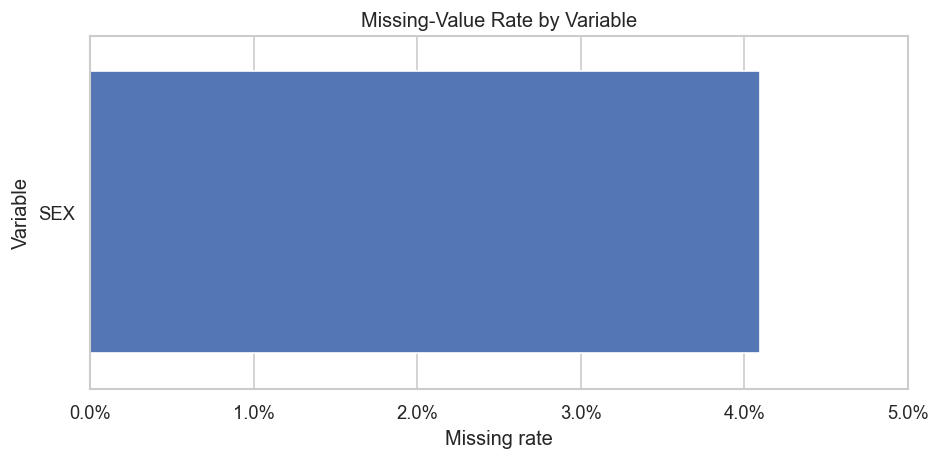

In [178]:
missing_summary = (
    training_data.isna()
    .sum()
    .rename("Missing count")
    .to_frame()
)

missing_summary["Missing rate"] = (
    missing_summary["Missing count"] / len(training_data)
)

missing_summary = (
    missing_summary[missing_summary["Missing count"] > 0]
    .sort_values("Missing rate", ascending=False)
)

display(
    missing_summary.style.format({
        "Missing rate": "{:.2%}"
    })
)

if not missing_summary.empty:
    missing_plot_data = missing_summary.reset_index().rename(
        columns={"index": "Variable"}
    )

    plt.figure(figsize=(8, 4))

    ax = sns.barplot(
        data=missing_plot_data,
        x="Missing rate",
        y="Variable",
        color="#4472C4"
    )

    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    plt.title("Missing-Value Rate by Variable")
    plt.xlabel("Missing rate")
    plt.ylabel("Variable")
    plt.xlim(
        0,
        max(
            0.05,
            missing_summary["Missing rate"].max() * 1.15
        )
    )
    plt.tight_layout()
    plt.show()
else:
    print("No missing values were detected.")

### Key Finding

Only `SEX` contains explicit missing values. Because its missing rate is limited, the observations are retained and missing values are represented by a separate `<MISSING>` category during preprocessing.

## 2.4. Duplicate Records and Label Consistency

Duplicate records are examined without automatic deletion because the dataset does not contain a unique loan or customer identifier.

In [179]:
exact_duplicate_count = int(
    training_data.duplicated().sum()
)

duplicated_feature_row_count = int(
    training_data.duplicated(
        subset=feature_columns,
        keep=False
    ).sum()
)

duplicate_group_summary = (
    training_data
    .groupby(feature_columns, dropna=False)
    .agg(
        Record_count=("NHOMNO", "size"),
        NHOMNO_unique=("NHOMNO", "nunique"),
        NHOMNOMOI_unique=("NHOMNOMOI", "nunique")
    )
    .reset_index()
)

duplicate_groups = duplicate_group_summary[
    duplicate_group_summary["Record_count"] > 1
].copy()

duplicate_quality_summary = pd.DataFrame({
    "Check": [
        "Exact duplicate rows",
        "Rows involved in feature duplicates",
        "Duplicated feature groups",
        "Groups with conflicting NHOMNO labels",
        "Groups with conflicting NHOMNOMOI labels"
    ],
    "Count": [
        exact_duplicate_count,
        duplicated_feature_row_count,
        len(duplicate_groups),
        int((duplicate_groups["NHOMNO_unique"] > 1).sum()),
        int((duplicate_groups["NHOMNOMOI_unique"] > 1).sum())
    ]
})

display(duplicate_quality_summary)

,Check,Count
0,Exact duplicate rows,44
1,Rows involved in feature duplicates,85
2,Duplicated feature groups,40
3,Groups with conflicting NHOMNO labels,0
4,Groups with conflicting NHOMNOMOI labels,1


### Key Finding

Duplicate records are retained because no unique loan identifier is available. A feature-based fingerprint will later be used to keep identical records in the same train or test partition and prevent leakage.

## 2.5. Target Distribution and Class Imbalance

The distributions of `NHOMNO` and `NHOMNOMOI` are examined because class imbalance can make accuracy misleading.

Target counts:


,NHOMNO,NHOMNOMOI
1,21347,20965
2,1094,1287
3,557,604
4,724,784
5,3279,3361


Target percentages:


,NHOMNO,NHOMNOMOI
1,79.06%,77.65%
2,4.05%,4.77%
3,2.06%,2.24%
4,2.68%,2.90%
5,12.14%,12.45%


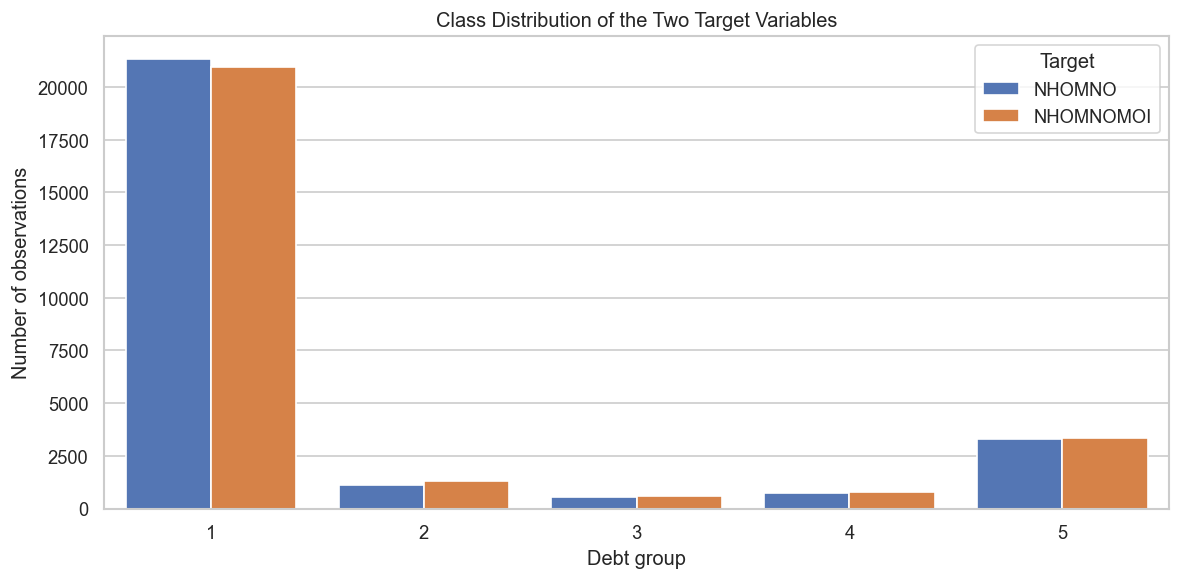

Number of records where NHOMNO differs from NHOMNOMOI: 456


In [180]:
target_distribution = pd.concat(
    {
        target: training_data[target]
        .value_counts()
        .sort_index()
        for target in target_columns
    },
    axis=1
)

target_distribution.columns = target_columns

target_distribution_percentage = (
    target_distribution
    .div(target_distribution.sum(axis=0), axis=1)
)

print("Target counts:")
display(target_distribution)

print("Target percentages:")
display(
    target_distribution_percentage.style.format("{:.2%}")
)

target_long = training_data[target_columns].melt(
    var_name="Target",
    value_name="Debt group"
)

plt.figure(figsize=(10, 5))

ax = sns.countplot(
    data=target_long,
    x="Debt group",
    hue="Target",
    palette=["#4472C4", "#ED7D31"]
)

plt.title("Class Distribution of the Two Target Variables")
plt.xlabel("Debt group")
plt.ylabel("Number of observations")
plt.legend(title="Target")
plt.tight_layout()
plt.show()

target_difference_count = int(
    (training_data["NHOMNO"] != training_data["NHOMNOMOI"]).sum()
)

print(
    "Number of records where NHOMNO differs from NHOMNOMOI:",
    target_difference_count
)

### Key Finding

Both targets are strongly imbalanced, with debt group 1 representing most observations. Model evaluation should therefore include macro-F1, class-level recall, confusion matrices, AUC, and Gini rather than relying on accuracy alone.r training folds.

## 2.6. Date Standardization and Logical Validation

The date variables contain both `dd/mm/yyyy` text and Excel serial numbers. They must be converted using a parser that supports both formats.y date.

In [181]:
def parse_mixed_excel_date(series):
    """Convert supported text dates and plausible Excel serial dates to datetime."""
    text_values = series.astype("string").str.strip().replace(
        {"": pd.NA, "nan": pd.NA, "NaN": pd.NA, "None": pd.NA, "<NA>": pd.NA}
    )

    parsed_dates = pd.Series(pd.NaT, index=series.index, dtype="datetime64[ns]")
    supported_formats = [
        "%d/%m/%Y", "%Y-%m-%d", "%d-%m-%Y", "%m/%d/%Y",
        "%Y/%m/%d", "%d/%m/%Y %H:%M:%S", "%Y-%m-%d %H:%M:%S",
    ]

    for date_format in supported_formats:
        remaining = parsed_dates.isna() & text_values.notna()
        if not remaining.any():
            break
        parsed_dates.loc[remaining] = pd.to_datetime(
            text_values.loc[remaining], format=date_format, errors="coerce"
        )

    numeric_values = pd.to_numeric(text_values, errors="coerce").replace(
        [np.inf, -np.inf], np.nan
    )
    valid_serial = numeric_values.between(1, 73050, inclusive="both")

    excel_dates = pd.Series(pd.NaT, index=series.index, dtype="datetime64[ns]")
    excel_dates.loc[valid_serial] = pd.to_datetime(
        numeric_values.loc[valid_serial],
        unit="D",
        origin="1899-12-30",
        errors="coerce",
    )

    return parsed_dates.fillna(excel_dates)


def convert_decimal_numeric(series):
    """Convert decimal-comma/decimal-point values and remove infinities."""
    cleaned = series.astype("string").str.strip().str.replace(",", ".", regex=False)
    return pd.to_numeric(cleaned, errors="coerce").replace([np.inf, -np.inf], np.nan)


def normalize_integer_code(series):
    """Normalize codes such as 4, 4.0 and '4.0' to the same category '4'."""
    numeric = pd.to_numeric(series, errors="coerce").replace([np.inf, -np.inf], np.nan)
    return numeric.round().astype("Int64").astype("string").fillna("<MISSING>")


def normalize_text_category(series):
    """Trim text categories and use an explicit missing category."""
    return series.astype("string").str.strip().fillna("<MISSING>")


open_date = parse_mixed_excel_date(training_data["OPEN_DATE"])
due_date = parse_mixed_excel_date(training_data["NGAYDENHAN"])

date_quality_summary = pd.DataFrame({
    "Variable": ["OPEN_DATE", "NGAYDENHAN"],
    "Parse failures": [int(open_date.isna().sum()), int(due_date.isna().sum())],
    "Minimum date": [open_date.min(), due_date.min()],
    "Maximum date": [open_date.max(), due_date.max()],
})

display(date_quality_summary)

,Variable,Parse failures,Minimum date,Maximum date
0,OPEN_DATE,0,2004-02-04,2020-11-08
1,NGAYDENHAN,0,2006-11-27,2067-12-28


In [182]:
loan_term_days = (due_date - open_date).dt.days

loan_term_summary = loan_term_days.describe(
    percentiles=[
        0.01,
        0.05,
        0.50,
        0.95,
        0.99
    ]
)

display(
    loan_term_summary.to_frame(
        name="Loan term in days"
    )
)

invalid_term_count = int(
    (loan_term_days <= 0).sum()
)

print(
    "Number of non-positive loan terms:",
    invalid_term_count
)

,Loan term in days
count,"27,001.0000"
mean,"2,292.4988"
std,"2,452.0153"
min,-197.0000
1%,365.0000
5%,366.0000
50%,"1,461.0000"
95%,"7,305.0000"
99%,"10,958.0000"
max,"18,292.0000"


Number of non-positive loan terms: 7


### Key Finding

Seven records have non-positive loan terms. These terms are converted to missing values and accompanied by an error flag rather than deleting the corresponding observations.y problem.

## 2.7. Numerical Variables and Outlier Analysis

Outliers are identified for diagnostic purposes. Large loan balances are not automatically removed because they may represent valid high-value exposures.

In [183]:
numeric_columns = [
    "BASE_BAL",
    "CURR_BAL",
    "DUNO_QD",
    "LAISUAT"
]

numeric_summary = (
    training_data[numeric_columns]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
    .T
)

iqr_outlier_records = []

for column in numeric_columns:
    numeric_series = pd.to_numeric(
        training_data[column],
        errors="coerce"
    )

    first_quartile = numeric_series.quantile(0.25)
    third_quartile = numeric_series.quantile(0.75)
    interquartile_range = (
        third_quartile - first_quartile
    )

    lower_bound = (
        first_quartile - 1.5 * interquartile_range
    )

    upper_bound = (
        third_quartile + 1.5 * interquartile_range
    )

    outlier_count = int(
        (
            (numeric_series < lower_bound)
            | (numeric_series > upper_bound)
        ).sum()
    )

    iqr_outlier_records.append({
        "Variable": column,
        "Lower IQR bound": lower_bound,
        "Upper IQR bound": upper_bound,
        "IQR outlier count": outlier_count,
        "Negative count": int((numeric_series < 0).sum()),
        "Zero count": int((numeric_series == 0).sum())
    })

iqr_outlier_summary = pd.DataFrame(
    iqr_outlier_records
)

display(numeric_summary)
display(iqr_outlier_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
BASE_BAL,"27,001.0000","428,020,131.5819","6,404,622,550.5189",2.0000,"75,000.0000","250,000.0000","5,000,000.0000","35,000,000.0000","250,000,000.0000","800,000,000.0000","2,500,000,000.0000","385,000,000,000.0000"
CURR_BAL,"27,001.0000","355,511,384.8324","5,324,972,876.4852",1.0000,1.0000,"178,350.0000","11,180,610.0000","44,000,000.0000","200,000,000.0000","714,617,450.0000","2,080,500,000.0000","296,000,000,000.0000"
DUNO_QD,"27,001.0000","355,511,384.8324","5,324,972,876.4852",1.0000,1.0000,"178,350.0000","11,180,610.0000","44,000,000.0000","200,000,000.0000","714,617,450.0000","2,080,500,000.0000","296,000,000,000.0000"
LAISUAT,"27,001.0000",0.0688,0.0681,0.0000,0.0000,0.0000,0.0000,0.1000,0.1210,0.1600,0.2257,0.4000


,Variable,Lower IQR bound,Upper IQR bound,IQR outlier count,Negative count,Zero count
0,BASE_BAL,"-362,500,000.0000","617,500,000.0000",1925,0,0
1,CURR_BAL,"-272,048,475.0000","483,229,085.0000",2462,0,0
2,DUNO_QD,"-272,048,475.0000","483,229,085.0000",2462,0,0
3,LAISUAT,-0.1815,0.3025,4,0,12784


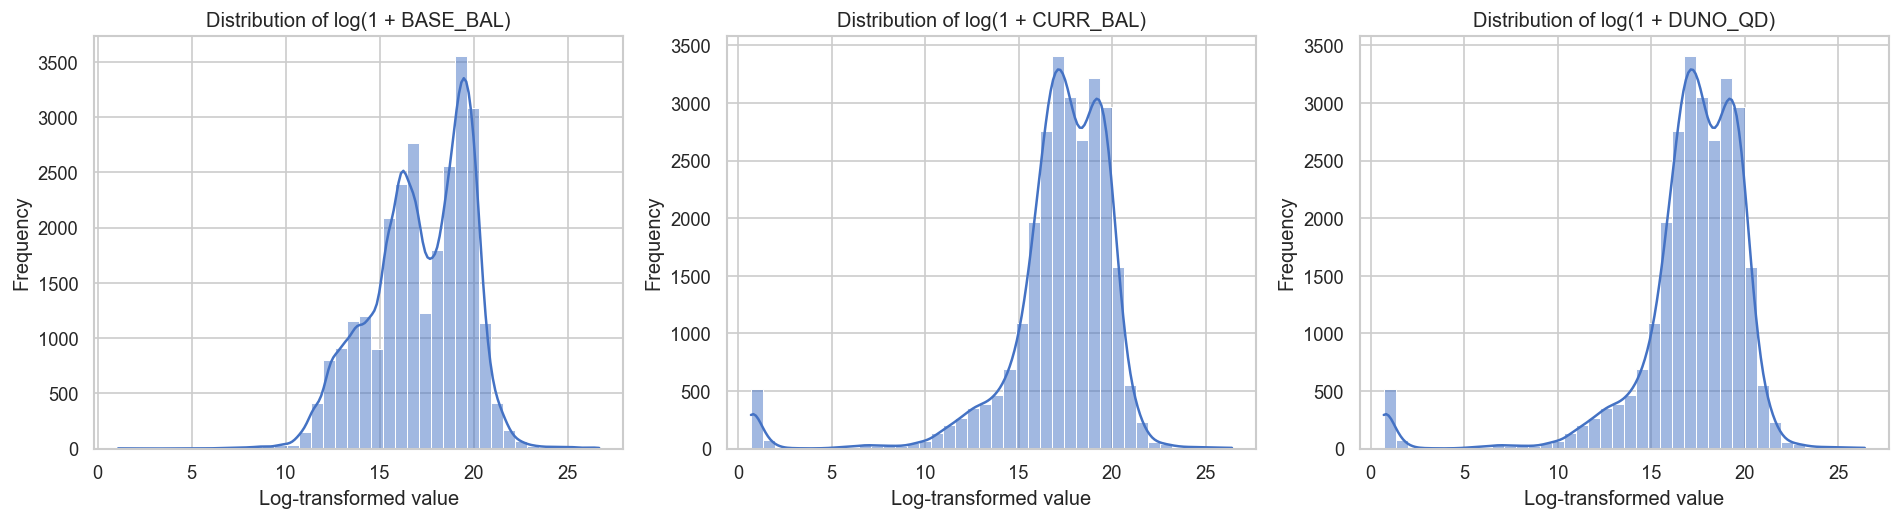

In [184]:
balance_columns = [
    "BASE_BAL",
    "CURR_BAL",
    "DUNO_QD"
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 4.5)
)

for axis, column in zip(axes, balance_columns):
    transformed_values = np.log1p(
        pd.to_numeric(
            training_data[column],
            errors="coerce"
        ).clip(lower=0)
    )

    sns.histplot(
        transformed_values,
        bins=40,
        kde=True,
        ax=axis,
        color="#4472C4"
    )

    axis.set_title(
        f"Distribution of log(1 + {column})"
    )
    axis.set_xlabel("Log-transformed value")
    axis.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

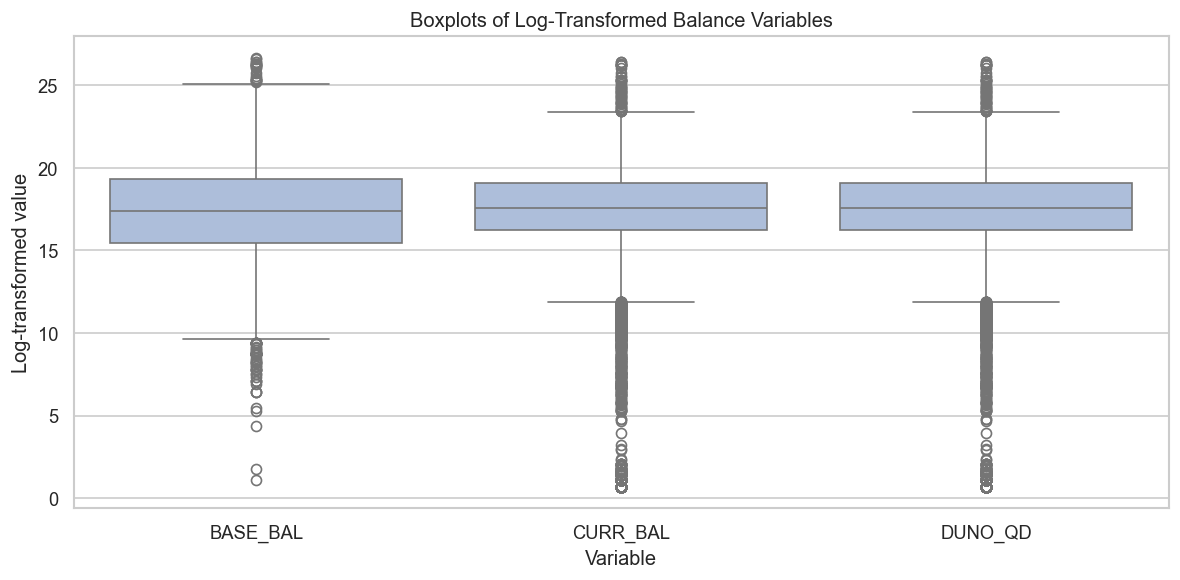

In [185]:
balance_plot_data = pd.DataFrame()

for column in balance_columns:
    balance_plot_data[column] = np.log1p(
        pd.to_numeric(
            training_data[column],
            errors="coerce"
        ).clip(lower=0)
    )

balance_plot_long = balance_plot_data.melt(
    var_name="Variable",
    value_name="Log-transformed value"
)

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=balance_plot_long,
    x="Variable",
    y="Log-transformed value",
    color="#A5BCE2"
)

plt.title("Boxplots of Log-Transformed Balance Variables")
plt.xlabel("Variable")
plt.ylabel("Log-transformed value")
plt.tight_layout()
plt.show()

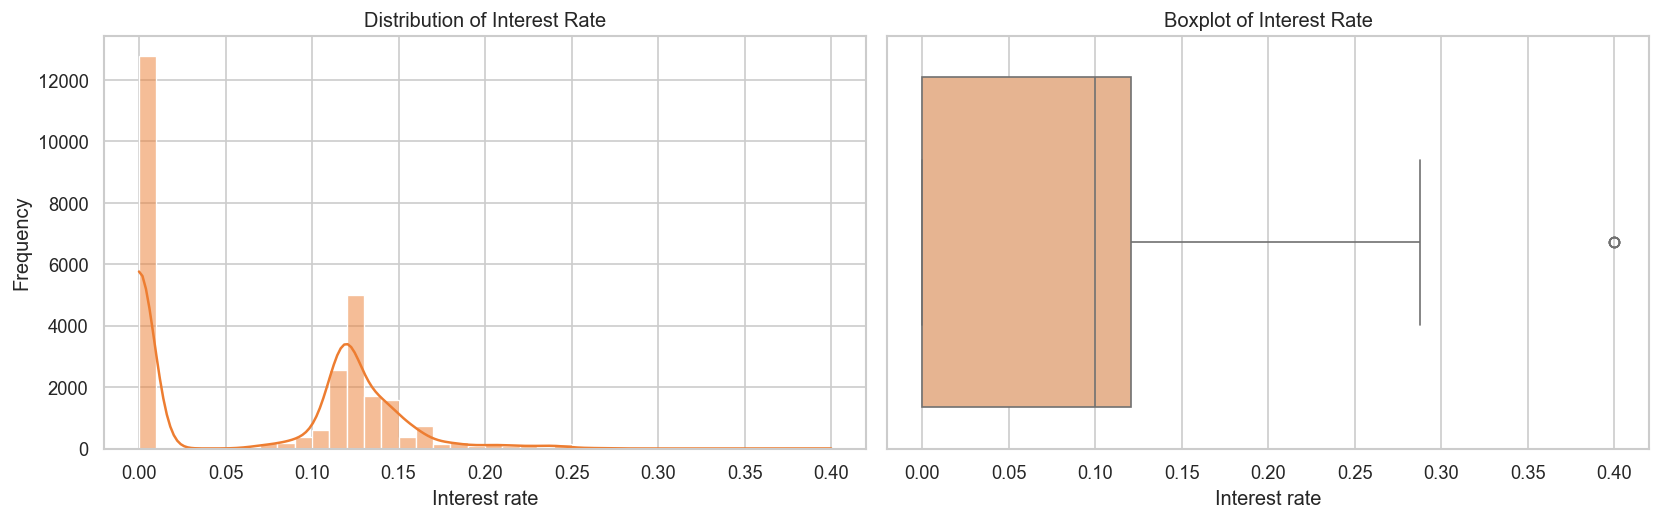

Number of zero-interest observations: 12784


In [186]:
interest_rate = pd.to_numeric(
    training_data["LAISUAT"],
    errors="coerce"
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 4.5)
)

sns.histplot(
    interest_rate,
    bins=40,
    kde=True,
    ax=axes[0],
    color="#ED7D31"
)

axes[0].set_title("Distribution of Interest Rate")
axes[0].set_xlabel("Interest rate")
axes[0].set_ylabel("Frequency")

sns.boxplot(
    x=interest_rate,
    ax=axes[1],
    color="#F4B183"
)

axes[1].set_title("Boxplot of Interest Rate")
axes[1].set_xlabel("Interest rate")

plt.tight_layout()
plt.show()

print(
    "Number of zero-interest observations:",
    int((interest_rate == 0).sum())
)

### Key Finding

The balance variables are strongly right-skewed and contain extreme values. The observations are retained, while `log1p` transformation is used to reduce skewness.

Zero interest rates are also retained because the dataset does not provide enough information to classify them as errors.

## 2.8. Redundant Variables

Variables containing identical or one-to-one information are examined to reduce multicollinearity and unnecessary dimensionality.

In [187]:
balance_equality_rate = np.isclose(
    pd.to_numeric(
        training_data["CURR_BAL"],
        errors="coerce"
    ),
    pd.to_numeric(
        training_data["DUNO_QD"],
        errors="coerce"
    ),
    equal_nan=True
).mean()

redundancy_summary = pd.DataFrame({
    "Check": [
        "CURR_BAL equals DUNO_QD",
        "Maximum descriptions per MJACCTTYPCD",
        "Maximum codes per MJACCTTYPDESC",
        "Maximum descriptions per ID_TIME",
        "Maximum codes per DESC_TIME",
        "Maximum descriptions per CURRMIACCTTYPCD",
        "Maximum codes per MIACCTTYPDESC"
    ],
    "Result": [
        balance_equality_rate,
        training_data.groupby("MJACCTTYPCD")[
            "MJACCTTYPDESC"
        ].nunique().max(),
        training_data.groupby("MJACCTTYPDESC")[
            "MJACCTTYPCD"
        ].nunique().max(),
        training_data.groupby("ID_TIME")[
            "DESC_TIME"
        ].nunique().max(),
        training_data.groupby("DESC_TIME")[
            "ID_TIME"
        ].nunique().max(),
        training_data.groupby("CURRMIACCTTYPCD")[
            "MIACCTTYPDESC"
        ].nunique().max(),
        training_data.groupby("MIACCTTYPDESC")[
            "CURRMIACCTTYPCD"
        ].nunique().max()
    ]
})

display(redundancy_summary)

,Check,Result
0,CURR_BAL equals DUNO_QD,1.0000
1,Maximum descriptions per MJACCTTYPCD,1.0000
2,Maximum codes per MJACCTTYPDESC,1.0000
3,Maximum descriptions per ID_TIME,1.0000
4,Maximum codes per DESC_TIME,1.0000
5,Maximum descriptions per CURRMIACCTTYPCD,2.0000
6,Maximum codes per MIACCTTYPDESC,3.0000


### Key Finding

`DUNO_QD` is removed because it is identical to `CURR_BAL`. One variable is also retained from each one-to-one code–description pair to reduce redundancy.same model.

## 2.9. Exploratory Analysis of Categorical Variables

Categorical distributions are examined to identify dominant groups, rare categories, missing categories, and potential differences in debt-group composition.

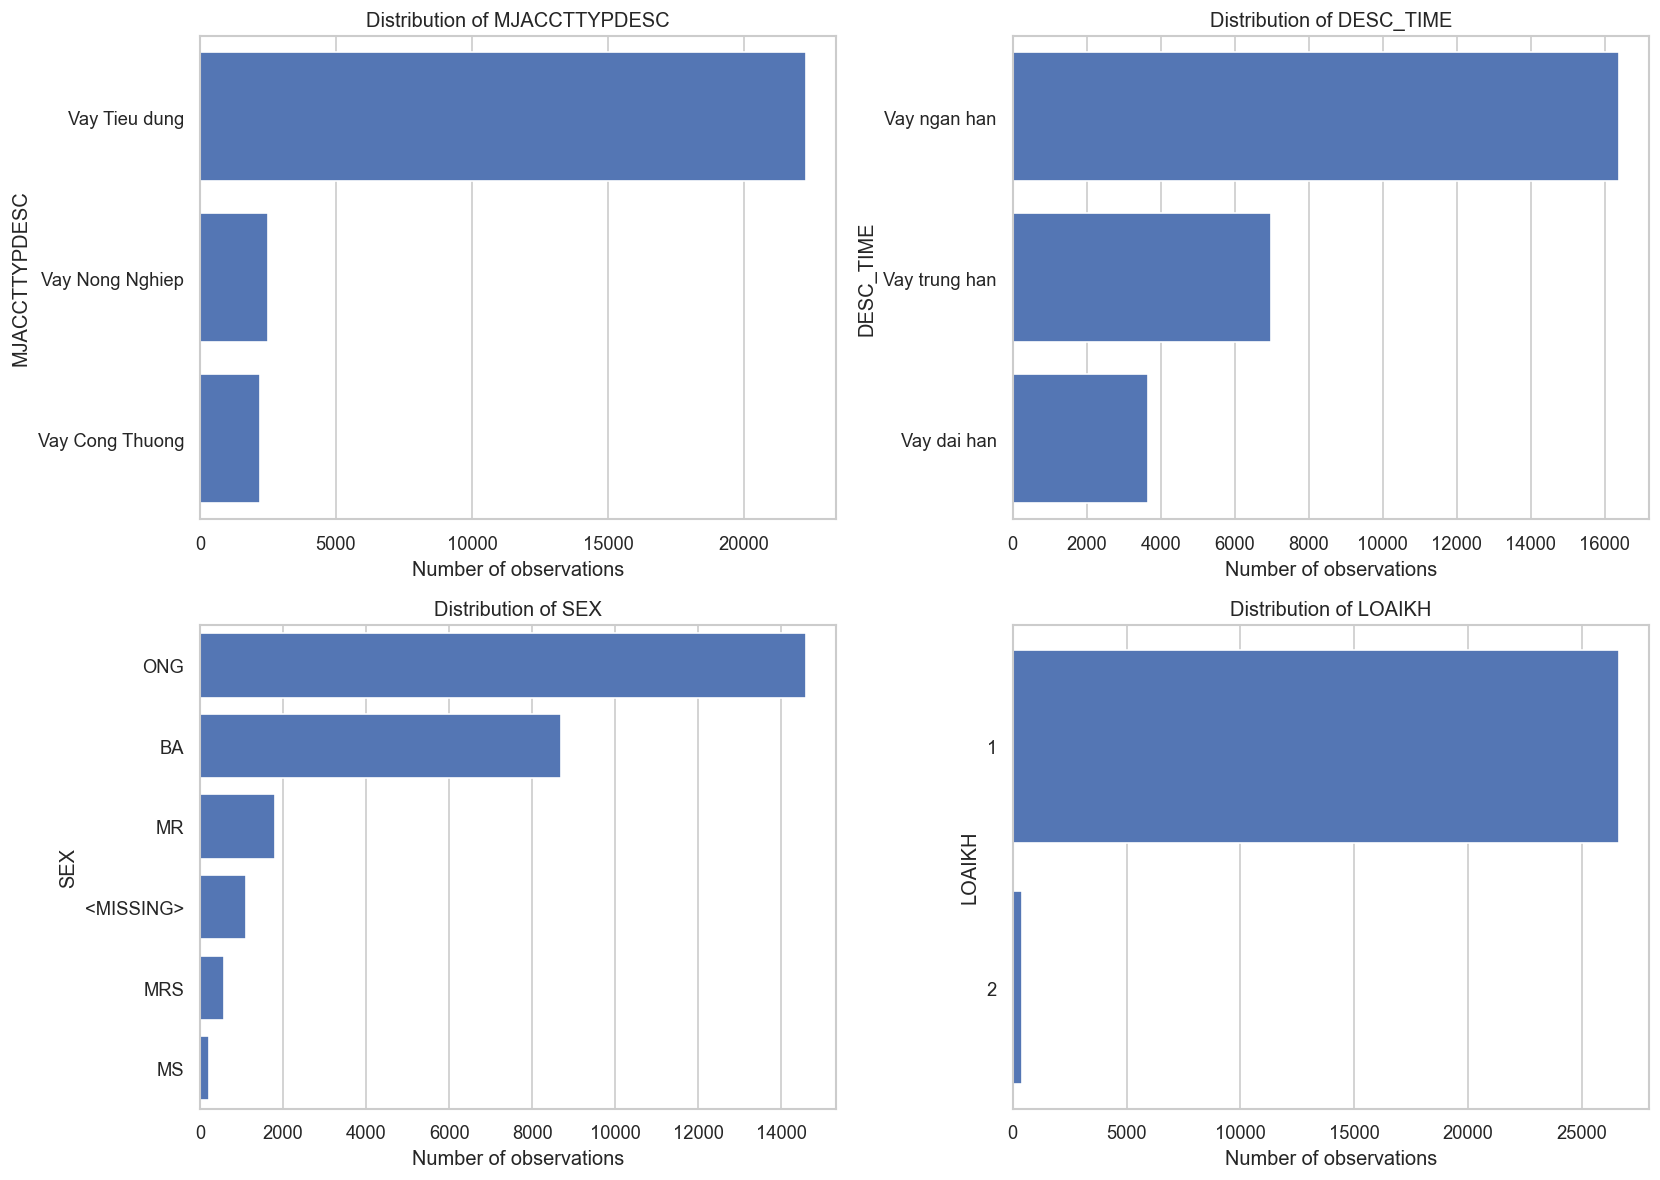

In [188]:
categorical_plot_columns = [
    "MJACCTTYPDESC",
    "DESC_TIME",
    "SEX",
    "LOAIKH"
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

for axis, column in zip(
    axes.flatten(),
    categorical_plot_columns
):
    category_counts = (
        training_data[column]
        .fillna("<MISSING>")
        .astype(str)
        .value_counts()
        .reset_index()
    )

    category_counts.columns = [
        column,
        "Count"
    ]

    sns.barplot(
        data=category_counts,
        x="Count",
        y=column,
        ax=axis,
        color="#4472C4"
    )

    axis.set_title(
        f"Distribution of {column}"
    )
    axis.set_xlabel(
        "Number of observations"
    )
    axis.set_ylabel(column)

plt.tight_layout()
plt.show()

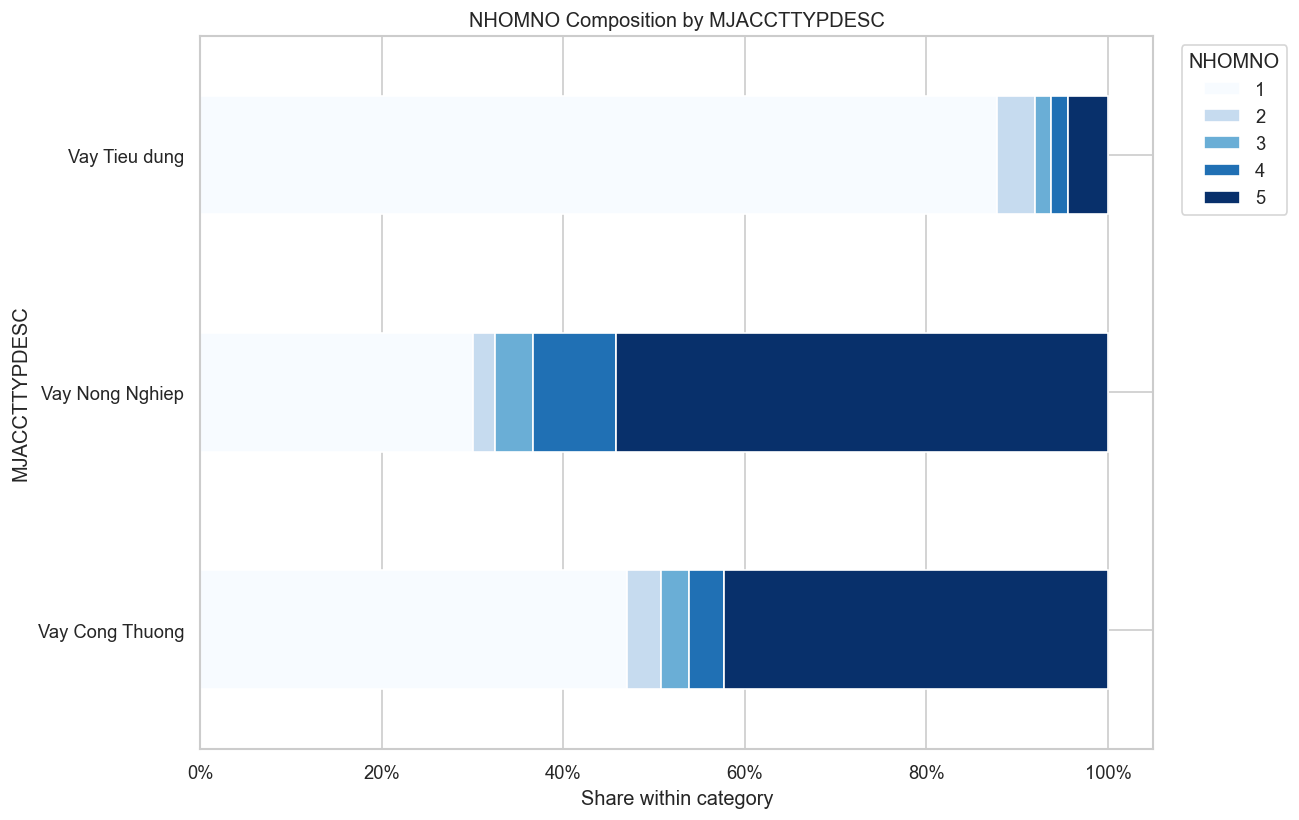

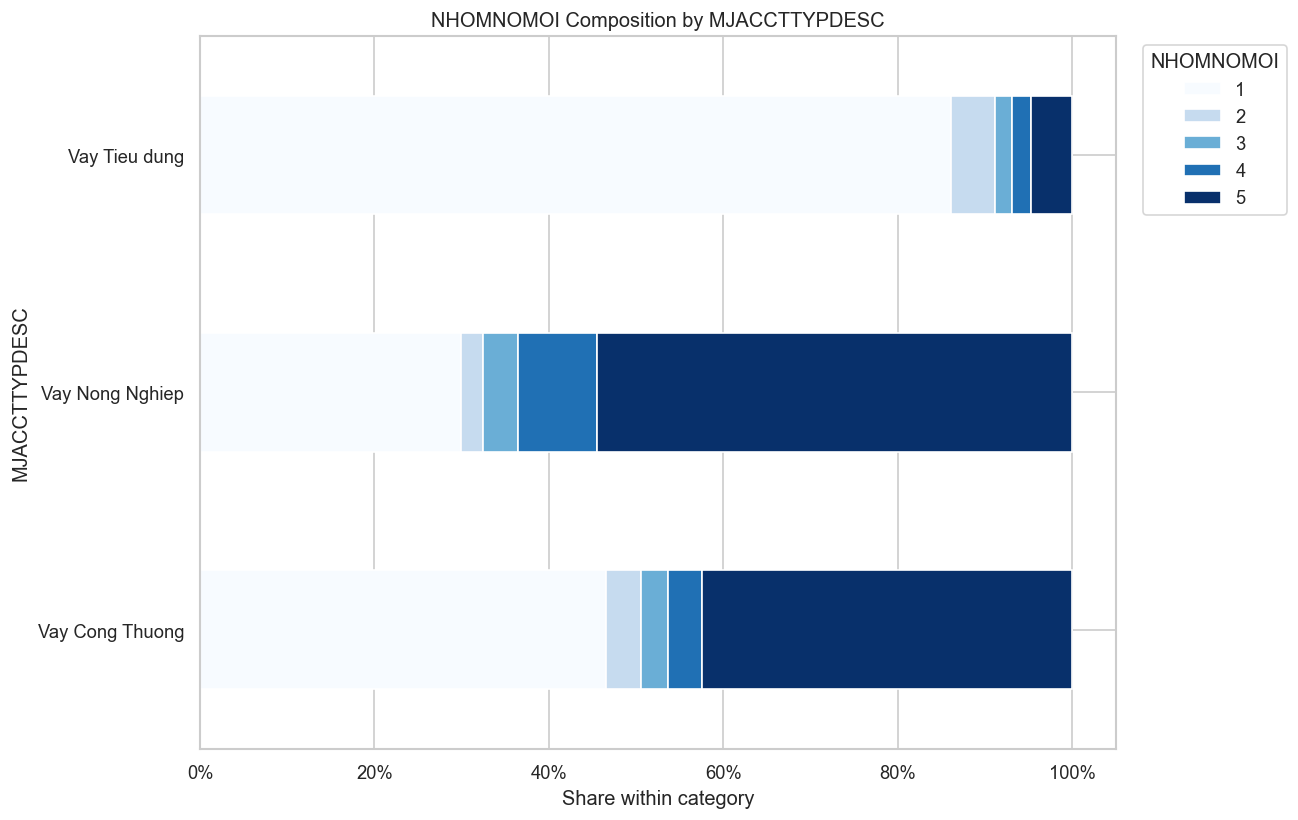

In [189]:
def plot_target_composition(
    data,
    category,
    target,
    top_n=12
):
    """
    Plot the within-category class composition
    for a multiclass target.
    """
    category_values = (
        data[category]
        .fillna("<MISSING>")
        .astype(str)
    )

    top_categories = (
        category_values
        .value_counts()
        .head(top_n)
        .index
    )

    plot_frame = data.loc[
        category_values.isin(top_categories),
        [category, target]
    ].copy()

    plot_frame[category] = (
        plot_frame[category]
        .fillna("<MISSING>")
        .astype(str)
    )

    composition = pd.crosstab(
        plot_frame[category],
        plot_frame[target],
        normalize="index"
    )

    composition.plot(
        kind="barh",
        stacked=True,
        figsize=(11, 7),
        colormap="Blues",
        edgecolor="white"
    )

    plt.title(
        f"{target} Composition by {category}"
    )
    plt.xlabel(
        "Share within category"
    )
    plt.ylabel(category)
    plt.gca().xaxis.set_major_formatter(
        PercentFormatter(1.0)
    )
    plt.legend(
        title=target,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )
    plt.tight_layout()
    plt.show()


plot_target_composition(
    data=training_data,
    category="MJACCTTYPDESC",
    target="NHOMNO"
)

plot_target_composition(
    data=training_data,
    category="MJACCTTYPDESC",
    target="NHOMNOMOI"
)

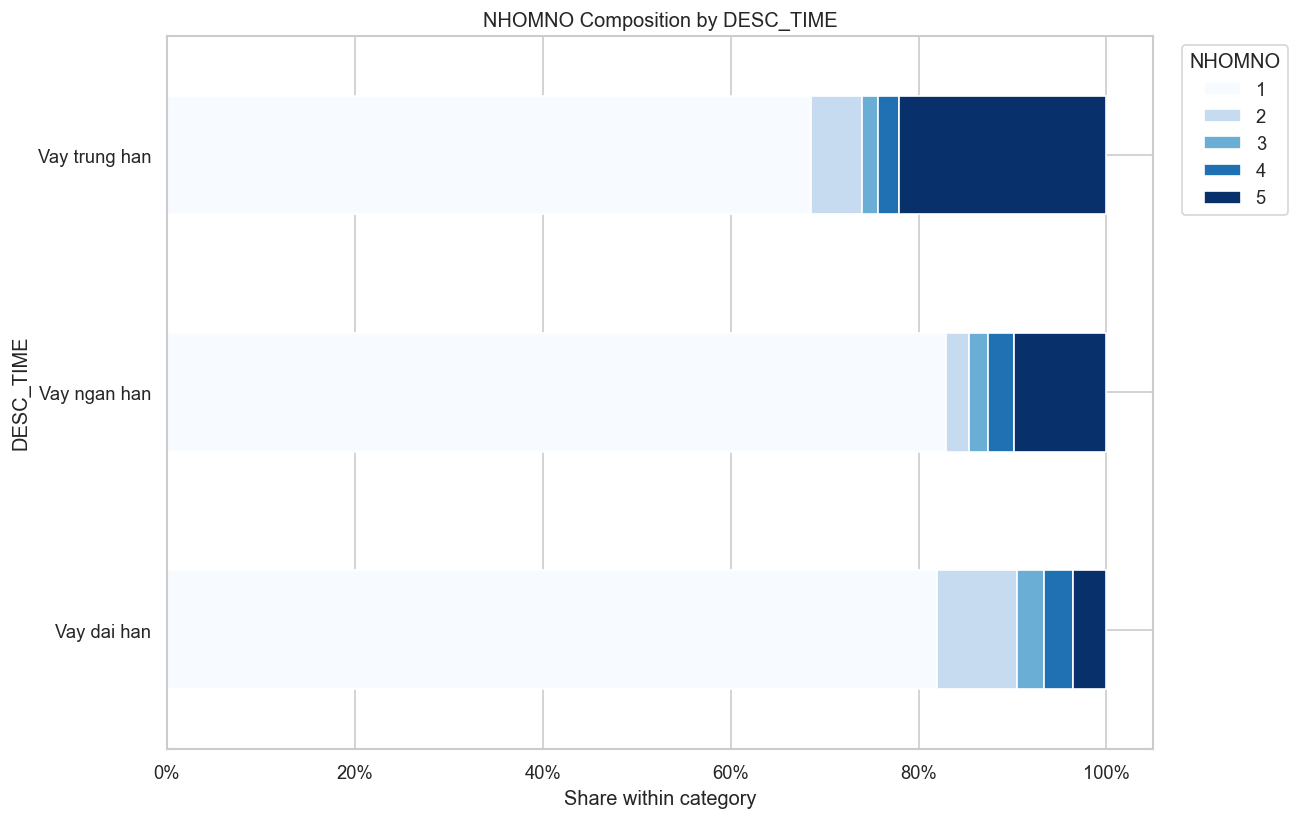

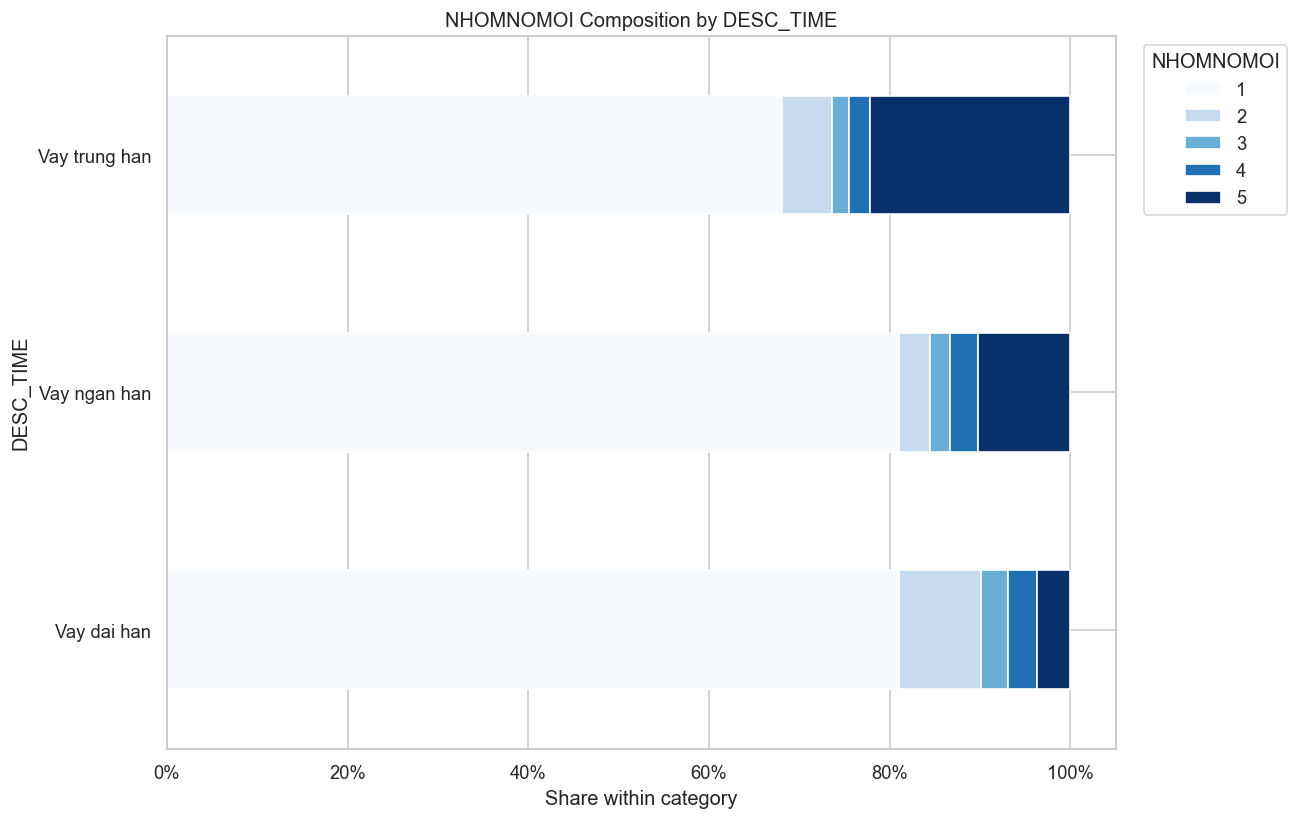

In [190]:
plot_target_composition(
    data=training_data,
    category="DESC_TIME",
    target="NHOMNO"
)

plot_target_composition(
    data=training_data,
    category="DESC_TIME",
    target="NHOMNOMOI"
)

### Key Finding

Loan type and maturity category show different debt-group compositions and may contain predictive information. These patterns represent association rather than causality.

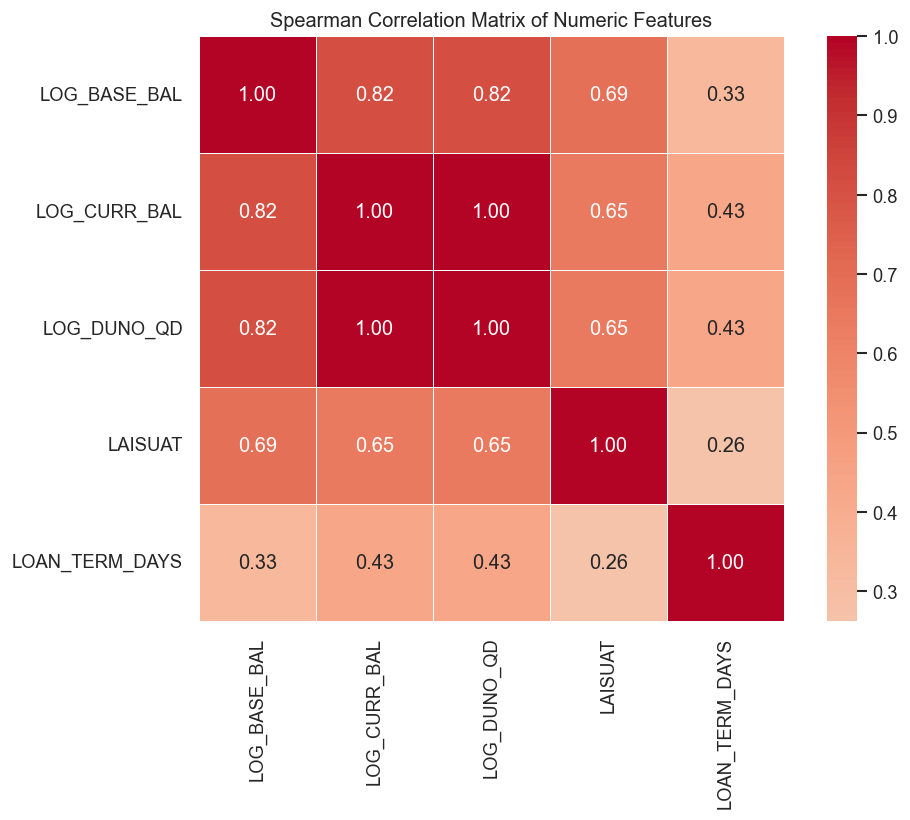

In [191]:
numeric_eda_data = pd.DataFrame({
    "LOG_BASE_BAL": np.log1p(
        pd.to_numeric(
            training_data["BASE_BAL"],
            errors="coerce"
        ).clip(lower=0)
    ),
    "LOG_CURR_BAL": np.log1p(
        pd.to_numeric(
            training_data["CURR_BAL"],
            errors="coerce"
        ).clip(lower=0)
    ),
    "LOG_DUNO_QD": np.log1p(
        pd.to_numeric(
            training_data["DUNO_QD"],
            errors="coerce"
        ).clip(lower=0)
    ),
    "LAISUAT": pd.to_numeric(
        training_data["LAISUAT"],
        errors="coerce"
    ),
    "LOAN_TERM_DAYS": loan_term_days
})

spearman_correlation = (
    numeric_eda_data.corr(
        method="spearman"
    )
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    spearman_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title(
    "Spearman Correlation Matrix of Numeric Features"
)
plt.tight_layout()
plt.show()

### Key Finding

`CURR_BAL` and `DUNO_QD` have perfect correlation because their values are identical. The remaining correlations are used for exploratory assessment and should not be interpreted as causal relationships.

## 2.10. Training–OOS Population Comparison

Feature distributions are compared to identify whether the OOS population differs materially from the model-development population.

,Training,OOS
MJACCTTYPDESC,,
Vay Tieu dung,82.51%,33.47%
Vay Nong Nghiep,9.26%,45.89%
Vay Cong Thuong,8.23%,20.64%


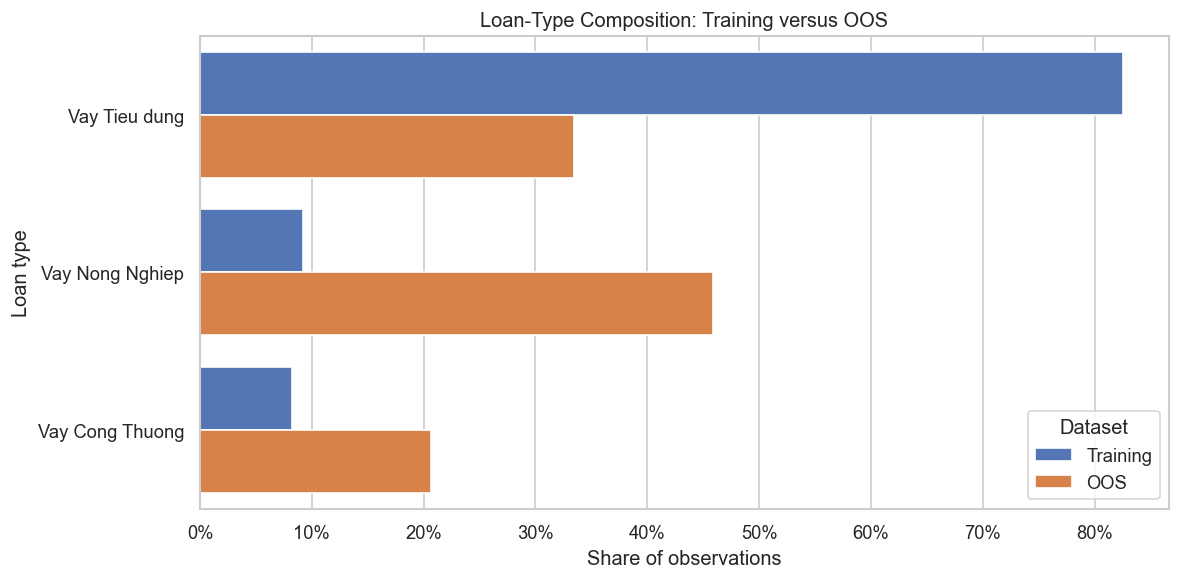

In [192]:
training_loan_mix = (
    training_data["MJACCTTYPDESC"]
    .value_counts(normalize=True)
    .rename("Training")
)

oos_loan_mix = (
    oos_data["MJACCTTYPDESC"]
    .value_counts(normalize=True)
    .rename("OOS")
)

population_mix = (
    pd.concat(
        [training_loan_mix, oos_loan_mix],
        axis=1
    )
    .fillna(0)
    .reset_index()
)

population_mix_long = population_mix.melt(
    id_vars="MJACCTTYPDESC",
    var_name="Dataset",
    value_name="Share"
)

display(
    population_mix.set_index(
        "MJACCTTYPDESC"
    ).style.format({
        "Training": "{:.2%}",
        "OOS": "{:.2%}"
    })
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=population_mix_long,
    x="Share",
    y="MJACCTTYPDESC",
    hue="Dataset",
    palette=["#4472C4", "#ED7D31"]
)

ax.xaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.title(
    "Loan-Type Composition: Training versus OOS"
)
plt.xlabel("Share of observations")
plt.ylabel("Loan type")
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

In [193]:
categorical_source_columns = [
    "MJACCTTYPCD", "CURRMIACCTTYPCD", "MIACCTTYPDESC", "LOAIKH", "SEX",
    "CURRENCYCD", "ID_TIME", "DESC_TIME", "MJACCTTYPDESC", "ORGNBR",
    "PARENTORGNBR", "MUCDICHVAY",
]

integer_code_columns = {"LOAIKH", "ID_TIME", "ORGNBR", "PARENTORGNBR"}
unseen_category_records = []

for column in categorical_source_columns:
    if column in integer_code_columns:
        training_values = normalize_integer_code(training_data[column])
        oos_values = normalize_integer_code(oos_data[column])
    else:
        training_values = normalize_text_category(training_data[column])
        oos_values = normalize_text_category(oos_data[column])

    training_categories = set(training_values.unique())
    oos_categories = set(oos_values.unique())
    unseen_categories = sorted(oos_categories - training_categories)

    unseen_category_records.append({
        "Variable": column,
        "Training category count": len(training_categories),
        "OOS category count": len(oos_categories),
        "Unseen OOS categories": unseen_categories,
        "Unseen category count": len(unseen_categories),
    })

unseen_category_summary = pd.DataFrame(unseen_category_records)
display(unseen_category_summary)

,Variable,Training category count,OOS category count,Unseen OOS categories,Unseen category count
0,MJACCTTYPCD,3,3,[],0
1,CURRMIACCTTYPCD,31,29,"[DH14, DH26, NH03, NH04, NH08, NH11, NH18, TH2...",10
2,MIACCTTYPDESC,27,26,"[CHO VAY THE TIN DUNG VND, CV DH CO CAU NO COV...",7
3,LOAIKH,2,2,[],0
4,SEX,6,6,[],0
5,CURRENCYCD,1,2,[USD],1
6,ID_TIME,3,3,[],0
7,DESC_TIME,3,3,[],0
8,MJACCTTYPDESC,3,3,[],0
9,ORGNBR,134,134,[],0


### Key Finding

The loan-type composition differs substantially between the training and OOS datasets. The OOS data also contain USD observations, whereas the training data contain only VND.

This population drift may reduce the transferability of test-set performance to the OOS predictions.

## 2.11. Feature Engineering

Feature engineering standardizes numerical and date fields, records invalid loan terms, and transforms highly skewed balance variables.

No feature is calculated relative to the current date because the dataset does not provide a valid observation date.

In [194]:
def prepare_credit_features(data):
    """Create model-ready features without modifying the source data."""
    prepared_data = data.copy()

    for column in ["BASE_BAL", "CURR_BAL", "DUNO_QD", "LAISUAT"]:
        if column in prepared_data.columns:
            prepared_data[column] = convert_decimal_numeric(prepared_data[column])

    for column in ["LOAIKH", "ID_TIME", "ORGNBR", "PARENTORGNBR"]:
        if column in prepared_data.columns:
            prepared_data[column] = normalize_integer_code(prepared_data[column])

    for column in [
        "MJACCTTYPCD", "CURRMIACCTTYPCD", "MIACCTTYPDESC", "SEX",
        "CURRENCYCD", "DESC_TIME", "MJACCTTYPDESC", "MUCDICHVAY",
    ]:
        if column in prepared_data.columns:
            prepared_data[column] = normalize_text_category(prepared_data[column])

    prepared_data["OPEN_DATE_PARSED"] = parse_mixed_excel_date(prepared_data["OPEN_DATE"])
    prepared_data["DUE_DATE_PARSED"] = parse_mixed_excel_date(prepared_data["NGAYDENHAN"])

    prepared_data["LOAN_TERM_DAYS"] = (
        prepared_data["DUE_DATE_PARSED"] - prepared_data["OPEN_DATE_PARSED"]
    ).dt.days.astype("float64")

    prepared_data["INVALID_TERM_FLAG"] = (
        prepared_data["LOAN_TERM_DAYS"] <= 0
    ).astype("int8")
    prepared_data.loc[
        prepared_data["LOAN_TERM_DAYS"] <= 0, "LOAN_TERM_DAYS"
    ] = np.nan

    prepared_data["OPEN_YEAR"] = prepared_data["OPEN_DATE_PARSED"].dt.year.astype("float64")
    prepared_data["DUE_YEAR"] = prepared_data["DUE_DATE_PARSED"].dt.year.astype("float64")

    prepared_data["LOG_BASE_BAL"] = np.log1p(prepared_data["BASE_BAL"].clip(lower=0))
    prepared_data["LOG_CURR_BAL"] = np.log1p(prepared_data["CURR_BAL"].clip(lower=0))
    prepared_data["ZERO_INTEREST_FLAG"] = (prepared_data["LAISUAT"] == 0).astype("int8")

    return prepared_data


prepared_training_data = prepare_credit_features(training_data)
prepared_oos_data = prepare_credit_features(oos_data)

print("Prepared training shape:", prepared_training_data.shape)
print("Prepared OOS shape:", prepared_oos_data.shape)

Prepared training shape: (27001, 30)
Prepared OOS shape: (25000, 27)


In [195]:
engineered_feature_summary = pd.DataFrame({
    "Variable": [
        "LOAN_TERM_DAYS",
        "OPEN_YEAR",
        "DUE_YEAR",
        "LOG_BASE_BAL",
        "LOG_CURR_BAL",
        "INVALID_TERM_FLAG",
        "ZERO_INTEREST_FLAG"
    ],
    "Missing count": [
        prepared_training_data[column]
        .isna()
        .sum()
        for column in [
            "LOAN_TERM_DAYS",
            "OPEN_YEAR",
            "DUE_YEAR",
            "LOG_BASE_BAL",
            "LOG_CURR_BAL",
            "INVALID_TERM_FLAG",
            "ZERO_INTEREST_FLAG"
        ]
    ],
    "Unique values": [
        prepared_training_data[column]
        .nunique(dropna=False)
        for column in [
            "LOAN_TERM_DAYS",
            "OPEN_YEAR",
            "DUE_YEAR",
            "LOG_BASE_BAL",
            "LOG_CURR_BAL",
            "INVALID_TERM_FLAG",
            "ZERO_INTEREST_FLAG"
        ]
    ]
})

display(engineered_feature_summary)

print(
    "Invalid loan-term flags:",
    int(
        prepared_training_data[
            "INVALID_TERM_FLAG"
        ].sum()
    )
)

print(
    "Zero-interest flags:",
    int(
        prepared_training_data[
            "ZERO_INTEREST_FLAG"
        ].sum()
    )
)

,Variable,Missing count,Unique values
0,LOAN_TERM_DAYS,7,1483
1,OPEN_YEAR,0,17
2,DUE_YEAR,0,54
3,LOG_BASE_BAL,0,6163
4,LOG_CURR_BAL,0,18346
5,INVALID_TERM_FLAG,0,2
6,ZERO_INTEREST_FLAG,0,2


Invalid loan-term flags: 7
Zero-interest flags: 12784


## 2.12. Leakage-Safe Splitting and Feature Selection

A deterministic fingerprint is created from the original input variables. A single approximately 80/20 holdout is used for both target variables, and identical feature records are always kept in the same partition.

The holdout is stratified by the joint pair `(NHOMNO, NHOMNOMOI)` so that the same test observations can be used for both targets. Mutual Information is fitted only on the development partition; the test partition is not used for preprocessing, feature selection, tuning, or model selection.

In [196]:
record_groups = pd.util.hash_pandas_object(
    training_data[feature_columns].astype("string").fillna("<MISSING>"),
    index=False,
)


def _group_level_strata(strata, groups):
    frame = pd.DataFrame({"group": np.asarray(groups), "stratum": np.asarray(strata)})
    # A duplicated-feature group should normally have one stratum. If labels conflict,
    # use the modal joint label only for partition construction and keep all rows together.
    return frame.groupby("group", sort=True)["stratum"].agg(
        lambda values: values.mode().iloc[0]
    )


def create_grouped_stratified_split(strata, groups, test_size=0.20, random_state=42):
    """Return deterministic row indices while keeping every group intact."""
    group_strata = _group_level_strata(strata, groups)
    group_ids = group_strata.index.to_numpy()

    development_groups, test_groups = train_test_split(
        group_ids,
        test_size=test_size,
        random_state=random_state,
        shuffle=True,
        stratify=group_strata.to_numpy(),
    )

    group_array = np.asarray(groups)
    development_index = np.flatnonzero(np.isin(group_array, development_groups))
    test_index = np.flatnonzero(np.isin(group_array, test_groups))
    return development_index, test_index


def create_group_stratified_cv_splits(target, groups, n_splits=3, random_state=42):
    """Create reproducible row-level CV splits from stratified unique groups."""
    group_targets = _group_level_strata(target, groups)
    group_ids = group_targets.index.to_numpy()
    group_array = np.asarray(groups)

    splitter = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    cv_splits = []
    for group_train_pos, group_valid_pos in splitter.split(group_ids, group_targets.to_numpy()):
        train_groups = group_ids[group_train_pos]
        valid_groups = group_ids[group_valid_pos]
        train_rows = np.flatnonzero(np.isin(group_array, train_groups))
        valid_rows = np.flatnonzero(np.isin(group_array, valid_groups))
        cv_splits.append((train_rows, valid_rows))

    return cv_splits


joint_strata = (
    training_data["NHOMNO"].astype(str)
    + "_"
    + training_data["NHOMNOMOI"].astype(str)
)

development_index, test_index = create_grouped_stratified_split(
    strata=joint_strata,
    groups=record_groups,
    test_size=0.20,
    random_state=RANDOM_SEED,
)

assert not set(record_groups.iloc[development_index]).intersection(
    set(record_groups.iloc[test_index])
)

print("Development observations:", len(development_index))
print("Held-out test observations:", len(test_index))
print("Duplicate groups shared across partitions: 0")

Development observations: 21602
Held-out test observations: 5399
Duplicate groups shared across partitions: 0


In [197]:
candidate_categorical_features = [
    "MJACCTTYPCD",
    "CURRMIACCTTYPCD",
    "LOAIKH",
    "SEX",
    "ID_TIME",
    "ORGNBR",
    "PARENTORGNBR",
    "MUCDICHVAY"
]

candidate_numeric_features = [
    "LOG_BASE_BAL",
    "LOG_CURR_BAL",
    "LAISUAT",
    "LOAN_TERM_DAYS",
    "OPEN_YEAR",
    "DUE_YEAR"
]

candidate_features = (
    candidate_categorical_features
    + candidate_numeric_features
)

# Ensure a consistent string type for categorical features
for column in candidate_categorical_features:
    prepared_training_data[column] = (
        prepared_training_data[column]
        .astype("string")
        .fillna("<MISSING>")
        .astype(str)
    )

feature_selection_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(
                            strategy="constant",
                            fill_value="<MISSING>"
                        )
                    ),
                    (
                        "encoder",
                        OrdinalEncoder(
                            handle_unknown="use_encoded_value",
                            unknown_value=-1
                        )
                    )
                ]
            ),
            candidate_categorical_features
        ),
        (
            "numeric",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(
                            strategy="median"
                        )
                    )
                ]
            ),
            candidate_numeric_features
        )
    ],
    verbose_feature_names_out=False
)

print("Candidate features:")
print(candidate_features)

Candidate features:
['MJACCTTYPCD', 'CURRMIACCTTYPCD', 'LOAIKH', 'SEX', 'ID_TIME', 'ORGNBR', 'PARENTORGNBR', 'MUCDICHVAY', 'LOG_BASE_BAL', 'LOG_CURR_BAL', 'LAISUAT', 'LOAN_TERM_DAYS', 'OPEN_YEAR', 'DUE_YEAR']


In [198]:
mutual_information_results = {}
split_indices = {
    target_name: {"train_index": development_index, "test_index": test_index}
    for target_name in target_columns
}

for target_name in target_columns:
    selection_train = prepared_training_data.iloc[development_index][candidate_features]
    selection_target = training_data.iloc[development_index][target_name]

    local_preprocessor = clone(feature_selection_preprocessor)
    transformed_selection_train = local_preprocessor.fit_transform(selection_train)

    discrete_feature_mask = (
        [True] * len(candidate_categorical_features)
        + [False] * len(candidate_numeric_features)
    )

    mutual_information_scores = mutual_info_classif(
        transformed_selection_train,
        selection_target,
        discrete_features=discrete_feature_mask,
        random_state=RANDOM_SEED,
    )

    score_table = pd.DataFrame({
        "Feature": candidate_features,
        "Mutual information": mutual_information_scores,
    }).sort_values("Mutual information", ascending=False).reset_index(drop=True)

    score_table.index = score_table.index + 1
    score_table.index.name = "Rank"
    mutual_information_results[target_name] = score_table

    development_distribution = (
        training_data.iloc[development_index][target_name]
        .value_counts(normalize=True).sort_index().rename("Development")
    )
    test_distribution = (
        training_data.iloc[test_index][target_name]
        .value_counts(normalize=True).sort_index().rename("Held-out test")
    )

    print(f"\nTarget: {target_name}")
    display(pd.concat([development_distribution, test_distribution], axis=1).style.format("{:.2%}"))
    display(score_table.style.format({"Mutual information": "{:.6f}"}))


Target: NHOMNO


,Development,Held-out test
NHOMNO,,
1,79.06%,79.05%
2,4.05%,4.07%
3,2.06%,2.06%
4,2.68%,2.69%
5,12.15%,12.13%


,Feature,Mutual information
Rank,,
1,DUE_YEAR,0.356879
2,CURRMIACCTTYPCD,0.326491
3,LAISUAT,0.274232
4,LOAN_TERM_DAYS,0.248689
5,MUCDICHVAY,0.186154
6,OPEN_YEAR,0.153834
7,ORGNBR,0.123864
8,MJACCTTYPCD,0.119313
9,LOG_CURR_BAL,0.103658



Target: NHOMNOMOI


,Development,Held-out test
NHOMNOMOI,,
1,77.65%,77.64%
2,4.76%,4.78%
3,2.24%,2.24%
4,2.90%,2.91%
5,12.45%,12.43%


,Feature,Mutual information
Rank,,
1,DUE_YEAR,0.343290
2,CURRMIACCTTYPCD,0.309947
3,LAISUAT,0.264584
4,LOAN_TERM_DAYS,0.241114
5,MUCDICHVAY,0.175332
6,OPEN_YEAR,0.152872
7,ORGNBR,0.128712
8,MJACCTTYPCD,0.115049
9,LOG_CURR_BAL,0.097465


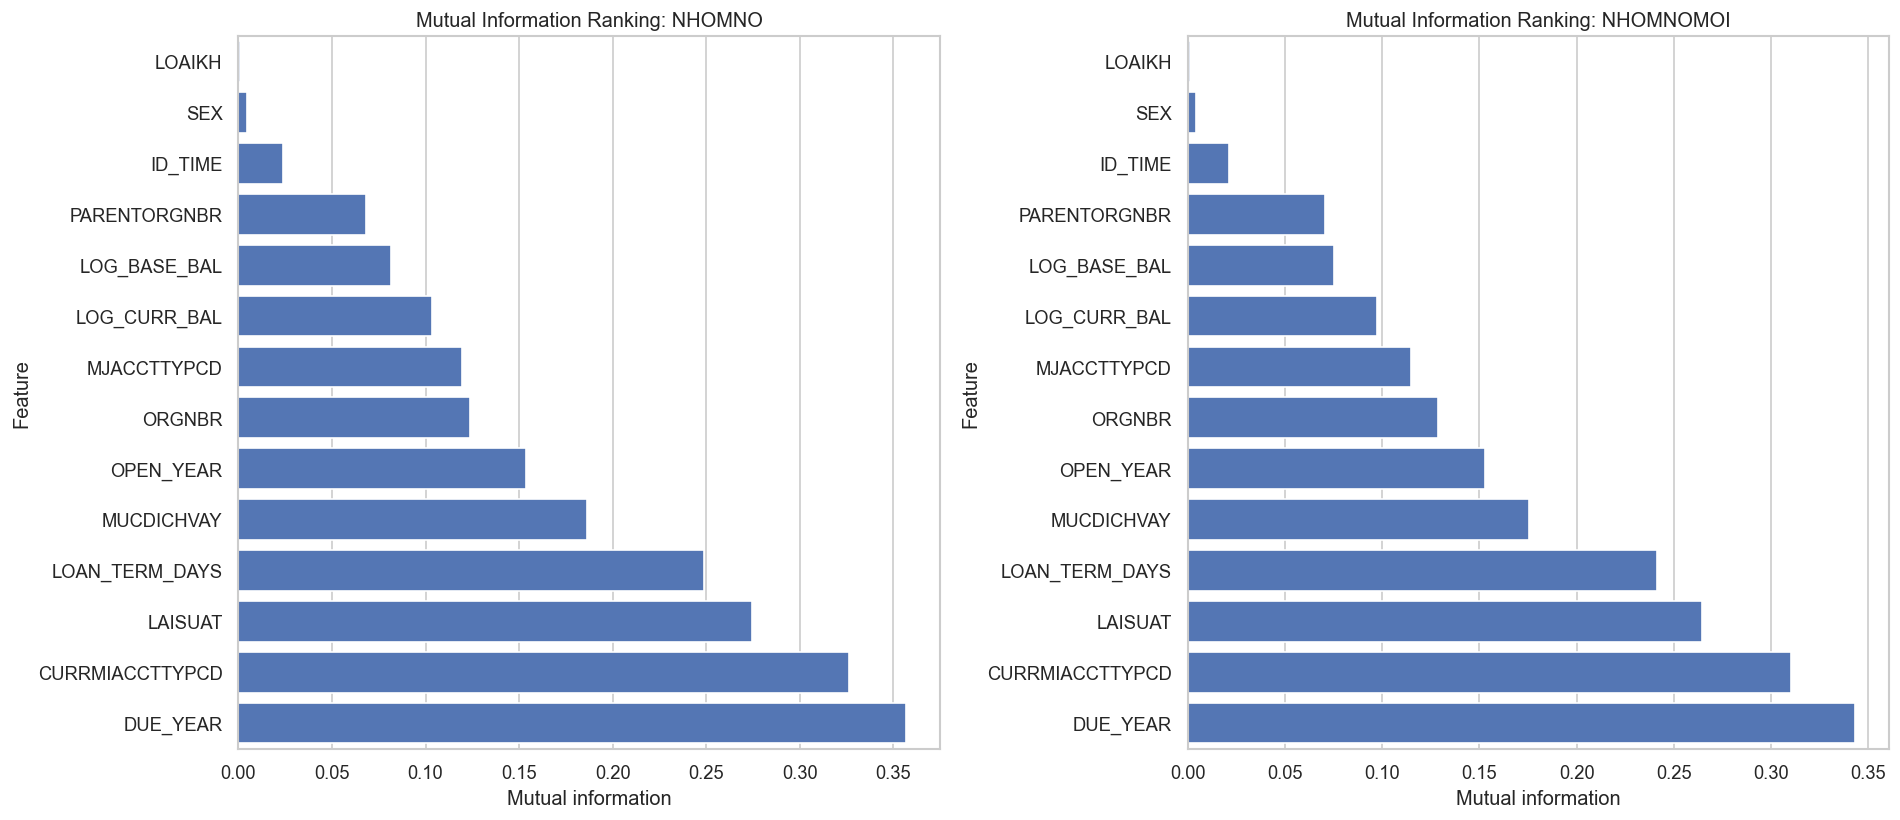

In [199]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7)
)

for axis, target_name in zip(
    axes,
    target_columns
):
    score_table = (
        mutual_information_results[
            target_name
        ]
        .sort_values(
            "Mutual information",
            ascending=True
        )
    )

    sns.barplot(
        data=score_table,
        x="Mutual information",
        y="Feature",
        ax=axis,
        color="#4472C4"
    )

    axis.set_title(
        f"Mutual Information Ranking: {target_name}"
    )
    axis.set_xlabel(
        "Mutual information"
    )
    axis.set_ylabel(
        "Feature"
    )

plt.tight_layout()
plt.show()

### Key Finding

Mutual Information identifies contractual dates, account type, interest rate, loan term, loan purpose, organizational codes, and balance measures as the strongest candidate predictors. Mutual Information measures predictive dependence rather than causality.

Calendar-year variables may act as temporal proxies, while organizational codes may be sensitive to population drift. These risks are examined again through temporal sensitivity analysis and OOS distribution checks.

In [200]:
mi_comparison = (
    mutual_information_results["NHOMNO"][["Feature", "Mutual information"]]
    .rename(columns={"Mutual information": "MI_NHOMNO"})
    .merge(
        mutual_information_results["NHOMNOMOI"][["Feature", "Mutual information"]]
        .rename(columns={"Mutual information": "MI_NHOMNOMOI"}),
        on="Feature",
        how="outer",
    )
)
mi_comparison["Mean_MI"] = mi_comparison[["MI_NHOMNO", "MI_NHOMNOMOI"]].mean(axis=1)

predeclared_exclusions = {
    "NHOMNO_TCBS": "Target-related variable with severe leakage risk",
    "DUNO_QD": "Identical to CURR_BAL across the training dataset",
    "MJACCTTYPDESC": "One-to-one mapping with MJACCTTYPCD",
    "DESC_TIME": "One-to-one mapping with ID_TIME",
    "MIACCTTYPDESC": "Largely redundant with CURRMIACCTTYPCD",
    "CURRENCYCD": "Constant in training and contains an unseen OOS category",
    "SEX": "Very low MI and potential fairness concerns",
    "LOAIKH": "Near-zero MI for both targets",
    "ID_TIME": "Low incremental value after deriving LOAN_TERM_DAYS",
}

selected_features = [
    "DUE_YEAR", "CURRMIACCTTYPCD", "LAISUAT", "LOAN_TERM_DAYS",
    "MUCDICHVAY", "OPEN_YEAR", "ORGNBR", "MJACCTTYPCD",
    "LOG_CURR_BAL", "LOG_BASE_BAL", "PARENTORGNBR",
]

selection_decision = mi_comparison.copy()
selection_decision["Selected"] = selection_decision["Feature"].isin(selected_features)
selection_decision["Decision reason"] = selection_decision["Feature"].map(
    lambda feature: (
        "Retained after MI ranking and leakage/redundancy review"
        if feature in selected_features
        else predeclared_exclusions.get(feature, "Not retained")
    )
)
selection_decision = selection_decision.sort_values(
    ["Selected", "Mean_MI"], ascending=[False, False]
).reset_index(drop=True)

display(selection_decision.style.format({
    "MI_NHOMNO": "{:.6f}", "MI_NHOMNOMOI": "{:.6f}", "Mean_MI": "{:.6f}"
}))

print("Selected features for Question 3:")
for feature in selected_features:
    print("-", feature)

,Feature,MI_NHOMNO,MI_NHOMNOMOI,Mean_MI,Selected,Decision reason
0,DUE_YEAR,0.356879,0.343290,0.350085,True,Retained after MI ranking and leakage/redundancy review
1,CURRMIACCTTYPCD,0.326491,0.309947,0.318219,True,Retained after MI ranking and leakage/redundancy review
2,LAISUAT,0.274232,0.264584,0.269408,True,Retained after MI ranking and leakage/redundancy review
3,LOAN_TERM_DAYS,0.248689,0.241114,0.244902,True,Retained after MI ranking and leakage/redundancy review
4,MUCDICHVAY,0.186154,0.175332,0.180743,True,Retained after MI ranking and leakage/redundancy review
5,OPEN_YEAR,0.153834,0.152872,0.153353,True,Retained after MI ranking and leakage/redundancy review
6,ORGNBR,0.123864,0.128712,0.126288,True,Retained after MI ranking and leakage/redundancy review
7,MJACCTTYPCD,0.119313,0.115049,0.117181,True,Retained after MI ranking and leakage/redundancy review
8,LOG_CURR_BAL,0.103658,0.097465,0.100561,True,Retained after MI ranking and leakage/redundancy review
9,LOG_BASE_BAL,0.081775,0.075503,0.078639,True,Retained after MI ranking and leakage/redundancy review


Selected features for Question 3:
- DUE_YEAR
- CURRMIACCTTYPCD
- LAISUAT
- LOAN_TERM_DAYS
- MUCDICHVAY
- OPEN_YEAR
- ORGNBR
- MJACCTTYPCD
- LOG_CURR_BAL
- LOG_BASE_BAL
- PARENTORGNBR


# Question 3 — Development, Evaluation, and Tuning of Credit Classification Models

This section develops two model groups for both `NHOMNO` and `NHOMNOMOI`:

1. **Traditional model:** Multinomial Logistic Regression.
2. **Non-traditional model:** Random Forest.

Both targets use the same held-out test observations. Preprocessing, feature selection, hyperparameter tuning, and final model selection use only the development data. The held-out test is evaluated only after the models have been selected by cross-validation.

In [201]:
import gc
import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize

print("Question 3 libraries imported successfully.")

Question 3 libraries imported successfully.


## 3.1. Modeling Strategy

Multinomial Logistic Regression is selected as the traditional method because it is interpretable and widely used in credit-risk modeling.

Random Forest is selected as the non-traditional method because it can capture nonlinear relationships and interactions without requiring a prespecified functional form.

Hyperparameter tuning uses macro-F1 as the optimization criterion because both targets are strongly imbalanced.

In [202]:
model_categorical_features = [
    "CURRMIACCTTYPCD",
    "MUCDICHVAY",
    "ORGNBR",
    "MJACCTTYPCD",
    "PARENTORGNBR"
]

model_numeric_features = [
    "DUE_YEAR",
    "LAISUAT",
    "LOAN_TERM_DAYS",
    "OPEN_YEAR",
    "LOG_CURR_BAL",
    "LOG_BASE_BAL"
]

model_features = (
    model_categorical_features
    + model_numeric_features
)

assert set(model_features) == set(selected_features)

X_model = prepared_training_data[
    model_features
].copy()

print("Categorical features:")
print(model_categorical_features)

print("\nNumerical features:")
print(model_numeric_features)

print("\nModeling data shape:", X_model.shape)

Categorical features:
['CURRMIACCTTYPCD', 'MUCDICHVAY', 'ORGNBR', 'MJACCTTYPCD', 'PARENTORGNBR']

Numerical features:
['DUE_YEAR', 'LAISUAT', 'LOAN_TERM_DAYS', 'OPEN_YEAR', 'LOG_CURR_BAL', 'LOG_BASE_BAL']

Modeling data shape: (27001, 11)


## 3.2. Leakage-Safe Preprocessing

Categorical variables are imputed and one-hot encoded. Previously unseen categories are ignored during transformation.

Numerical variables are median-imputed. Standardization is applied to Logistic Regression but is not required for Random Forest.

In [203]:
def create_model_preprocessor(scale_numeric=False):
    """
    Create preprocessing steps for categorical and numerical features.
    """
    numeric_steps = [
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]

    if scale_numeric:
        numeric_steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                Pipeline(
                    steps=[
                        (
                            "imputer",
                            SimpleImputer(
                                strategy="constant",
                                fill_value="<MISSING>"
                            )
                        ),
                        (
                            "onehot",
                            OneHotEncoder(
                                handle_unknown="ignore",
                                min_frequency=20
                            )
                        )
                    ]
                ),
                model_categorical_features
            ),
            (
                "numerical",
                Pipeline(
                    steps=numeric_steps
                ),
                model_numeric_features
            )
        ]
    )

    return preprocessor

## 3.3. Evaluation Metrics

Because the targets contain five ordered debt groups, there is no single binary “positive class” in this assignment. The notebook reports multiclass accuracy, balanced accuracy, macro precision/recall/F1, weighted F1, macro one-vs-rest AUC and Gini, multiclass Brier score, mean absolute class error, and the rate of severe errors where the predicted and actual groups differ by at least two levels.

Macro metrics are emphasized because group 1 is dominant. Gini is explicitly reported as **Macro OvR Gini**, not as the conventional binary default-model Gini.

In [204]:
def calculate_model_metrics(y_true, y_pred, y_probability, class_labels):
    """Calculate multiclass classification, discrimination, calibration and severity metrics."""
    class_labels = np.asarray(class_labels)
    auc_macro = roc_auc_score(
        y_true,
        y_probability,
        labels=class_labels,
        multi_class="ovr",
        average="macro",
    )

    y_binary = label_binarize(y_true, classes=class_labels)
    multiclass_brier = np.mean(np.sum((y_binary - y_probability) ** 2, axis=1))

    y_true_numeric = pd.to_numeric(pd.Series(y_true), errors="coerce").to_numpy()
    y_pred_numeric = pd.to_numeric(pd.Series(y_pred), errors="coerce").to_numpy()
    absolute_class_error = np.abs(y_true_numeric - y_pred_numeric)

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "AUC OvR macro": auc_macro,
        "Gini OvR macro": 2 * auc_macro - 1,
        "Multiclass Brier": multiclass_brier,
        "Mean absolute class error": float(np.mean(absolute_class_error)),
        "Severe error rate": float(np.mean(absolute_class_error >= 2)),
    }


def evaluate_model(fitted_model, X_test, y_test, target_name, model_name, model_version):
    """Evaluate a fitted pipeline and retain all outputs required for audit."""
    y_pred = fitted_model.predict(X_test)
    y_probability = fitted_model.predict_proba(X_test)
    class_labels = np.asarray(fitted_model.classes_)

    metrics = calculate_model_metrics(
        y_true=y_test,
        y_pred=y_pred,
        y_probability=y_probability,
        class_labels=class_labels,
    )

    report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        output_dict=True,
        zero_division=0,
    )
    matrix = confusion_matrix(y_test, y_pred, labels=class_labels)

    return {
        "result": {
            "Target": target_name,
            "Model": model_name,
            "Version": model_version,
            **metrics,
        },
        "predictions": y_pred,
        "probabilities": y_probability,
        "classes": class_labels,
        "classification_report": report,
        "confusion_matrix": matrix,
    }

In [205]:
model_splits = {}

for target_name in target_columns:
    X_development = X_model.iloc[development_index].copy()
    X_test = X_model.iloc[test_index].copy()
    y_development = training_data[target_name].iloc[development_index].copy()
    y_test = training_data[target_name].iloc[test_index].copy()
    groups_development = record_groups.iloc[development_index].copy()

    cv_splits = create_group_stratified_cv_splits(
        target=y_development,
        groups=groups_development,
        n_splits=3,
        random_state=RANDOM_SEED,
    )

    model_splits[target_name] = {
        "train_index": development_index,
        "test_index": test_index,
        "X_train": X_development,
        "X_test": X_test,
        "y_train": y_development,
        "y_test": y_test,
        "groups_train": groups_development,
        "cv_splits": cv_splits,
    }

    train_distribution = y_development.value_counts(normalize=True).sort_index().rename("Development")
    test_distribution = y_test.value_counts(normalize=True).sort_index().rename("Held-out test")

    print(f"\nTarget: {target_name}")
    print("Development observations:", len(development_index))
    print("Held-out test observations:", len(test_index))
    display(pd.concat([train_distribution, test_distribution], axis=1).style.format("{:.2%}"))


Target: NHOMNO
Development observations: 21602
Held-out test observations: 5399


,Development,Held-out test
NHOMNO,,
1,79.06%,79.05%
2,4.05%,4.07%
3,2.06%,2.06%
4,2.68%,2.69%
5,12.15%,12.13%



Target: NHOMNOMOI
Development observations: 21602
Held-out test observations: 5399


,Development,Held-out test
NHOMNOMOI,,
1,77.65%,77.64%
2,4.76%,4.78%
3,2.24%,2.24%
4,2.90%,2.91%
5,12.45%,12.43%


### Key Check

The target distributions are approximately preserved between the training and test partitions. Identical feature records are kept in the same partition through group-aware splitting.

## 3.4. Baseline Models

Both baseline models use class weighting to reduce the dominance of debt group 1. Their results establish a reference for evaluating whether hyperparameter tuning provides meaningful improvement.

In [206]:
def create_baseline_logistic_model():
    return Pipeline(
        steps=[
            (
                "preprocess",
                create_model_preprocessor(
                    scale_numeric=True
                )
            ),
            (
                "model",
                LogisticRegression(
                    C=1.0,
                    solver="lbfgs",
                    class_weight="balanced",
                    max_iter=2000,
                    random_state=RANDOM_SEED
                )
            )
        ]
    )


def create_baseline_random_forest():
    return Pipeline(
        steps=[
            (
                "preprocess",
                create_model_preprocessor(
                    scale_numeric=False
                )
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=60,
                    max_depth=18,
                    min_samples_split=2,
                    min_samples_leaf=3,
                    max_features="sqrt",
                    class_weight="balanced_subsample",
                    n_jobs=1,
                    random_state=RANDOM_SEED
                )
            )
        ]
    )

In [207]:
baseline_models = {}
model_evaluations = {}
model_result_rows = []

for target_name in target_columns:
    split_data = model_splits[
        target_name
    ]

    baseline_models[target_name] = {
        "Logistic Regression": (
            create_baseline_logistic_model()
        ),
        "Random Forest": (
            create_baseline_random_forest()
        )
    }

    for model_name, model in baseline_models[
        target_name
    ].items():
        start_time = time.time()

        model.fit(
            split_data["X_train"],
            split_data["y_train"]
        )

        elapsed_time = (
            time.time() - start_time
        )

        evaluation = evaluate_model(
            fitted_model=model,
            X_test=split_data["X_test"],
            y_test=split_data["y_test"],
            target_name=target_name,
            model_name=model_name,
            model_version="Baseline"
        )

        evaluation[
            "result"
        ]["Training time (seconds)"] = elapsed_time

        model_evaluations[
            (
                target_name,
                model_name,
                "Baseline"
            )
        ] = evaluation

        model_result_rows.append(
            evaluation["result"]
        )

baseline_results = pd.DataFrame(
    model_result_rows
)

display(
    baseline_results.style.format({
        column: "{:.4f}"
        for column in [
            "Accuracy",
            "Balanced accuracy",
            "Macro precision",
            "Macro recall",
            "Macro F1",
            "Weighted F1",
            "AUC OvR macro",
            "Gini OvR macro",
            "Multiclass Brier",
            "Mean absolute class error",
            "Severe error rate",
            "Training time (seconds)"
        ]
    })
)

,Target,Model,Version,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,AUC OvR macro,Gini OvR macro,Multiclass Brier,Mean absolute class error,Severe error rate,Training time (seconds)
0,NHOMNO,Logistic Regression,Baseline,0.6447,0.5185,0.4349,0.5185,0.4180,0.7332,0.8576,0.7153,0.4455,0.5803,0.1574,0.7700
1,NHOMNO,Random Forest,Baseline,0.7120,0.6246,0.5328,0.6246,0.5219,0.7835,0.9170,0.8339,0.3353,0.3697,0.0495,1.8811
2,NHOMNOMOI,Logistic Regression,Baseline,0.6205,0.5122,0.4347,0.5122,0.4140,0.7085,0.8385,0.6769,0.4837,0.6403,0.1791,0.7474
3,NHOMNOMOI,Random Forest,Baseline,0.7244,0.5896,0.5189,0.5896,0.5144,0.7854,0.8900,0.7800,0.3851,0.3749,0.0611,1.9092


### Baseline Finding

Random Forest substantially outperforms Logistic Regression for both targets in accuracy, macro-F1, weighted F1, AUC, and Gini. This indicates that nonlinear effects and feature interactions are important in the dataset.

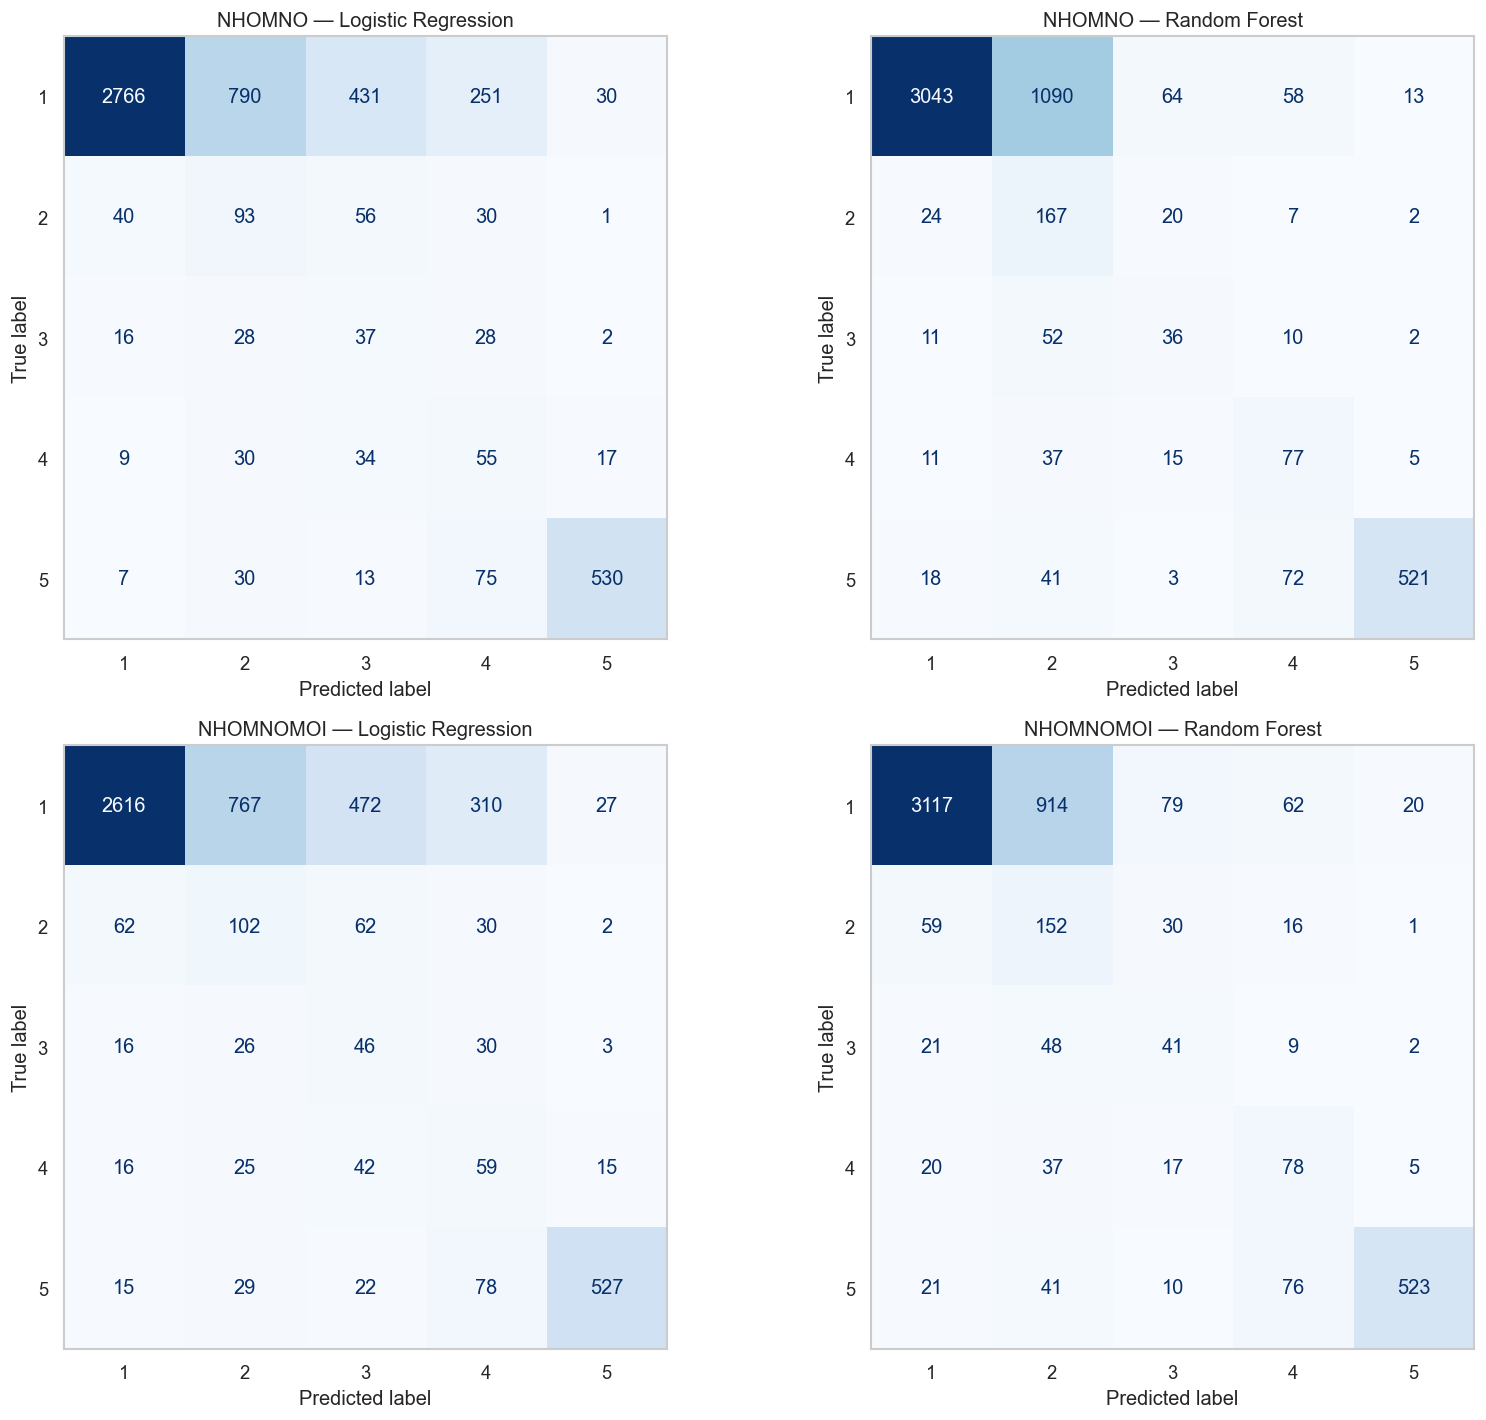

In [ ]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 12)
)

plot_positions = [
    ("NHOMNO", "Logistic Regression"),
    ("NHOMNO", "Random Forest"),
    ("NHOMNOMOI", "Logistic Regression"),
    ("NHOMNOMOI", "Random Forest")
]

for axis, (
    target_name,
    model_name
) in zip(
    axes.flatten(),
    plot_positions
):
    evaluation = model_evaluations[
        (
            target_name,
            model_name,
            "Baseline"
        )
    ]

    display_object = ConfusionMatrixDisplay(
        confusion_matrix=(
            evaluation["confusion_matrix"]
        ),
        display_labels=(
            evaluation["classes"]
        )
    )

    display_object.plot(
        ax=axis,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    axis.grid(
        False,
        which="both"
    )

    axis.set_title(
        f"{target_name} — {model_name}"
    )

plt.tight_layout()
plt.show()

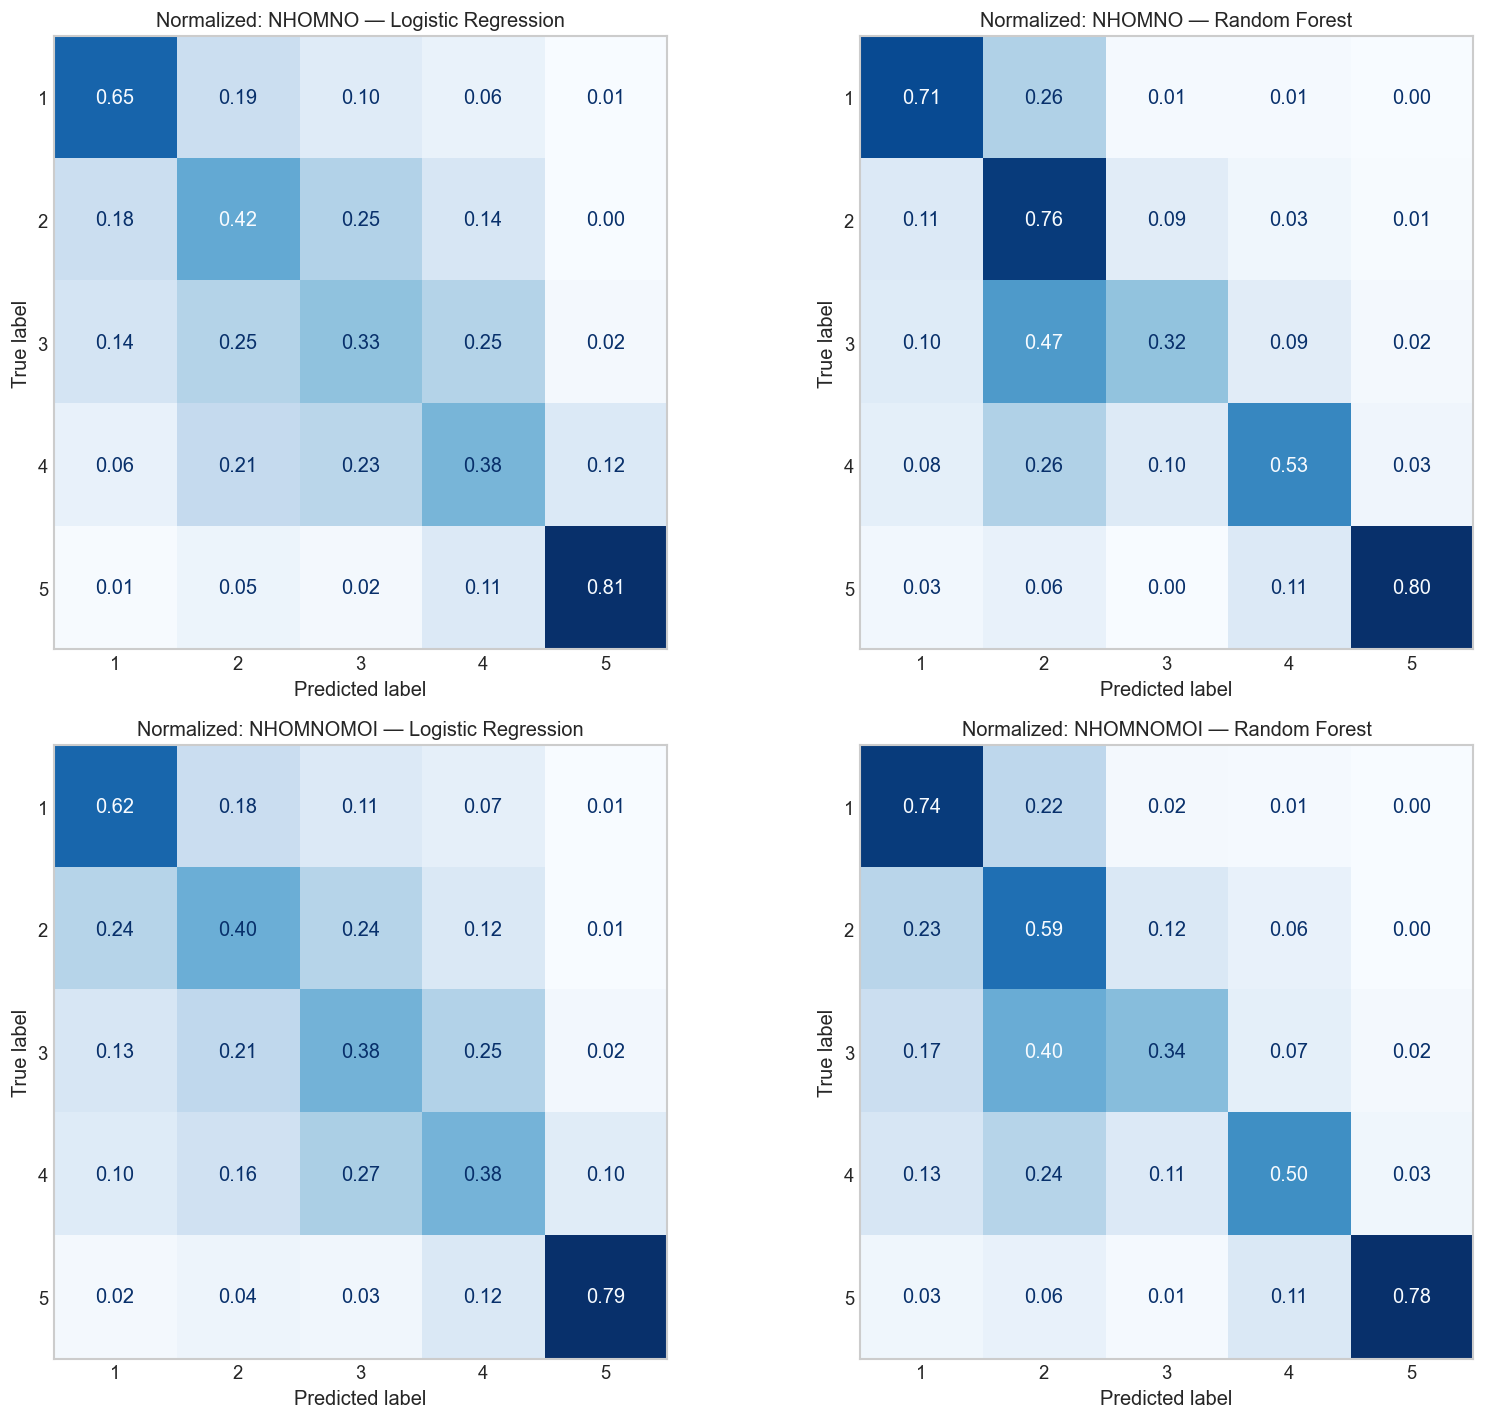

In [209]:
plt.rcParams["axes.grid"] = False

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 12)
)

for axis, (
    target_name,
    model_name
) in zip(
    axes.flatten(),
    plot_positions
):
    evaluation = model_evaluations[
        (
            target_name,
            model_name,
            "Baseline"
        )
    ]

    matrix = evaluation["confusion_matrix"].astype(float)
    row_totals = matrix.sum(
        axis=1,
        keepdims=True
    )

    normalized_matrix = np.divide(
        matrix,
        row_totals,
        out=np.zeros_like(matrix),
        where=row_totals != 0
    )

    display_object = ConfusionMatrixDisplay(
        confusion_matrix=normalized_matrix,
        display_labels=evaluation["classes"]
    )

    display_object.plot(
        ax=axis,
        cmap="Blues",
        colorbar=False,
        values_format=".2f"
    )

    axis.grid(False)
    axis.minorticks_off()

    axis.tick_params(
        axis="both",
        which="both",
        length=0
    )

    axis.set_title(
        f"Normalized: {target_name} — {model_name}"
    )

plt.tight_layout()
plt.show()

### Key Finding

The normalized confusion matrices should be used to assess minority-class recall. Accuracy is influenced heavily by debt group 1 and does not fully represent performance for debt groups 2–4.

In [210]:
for target_name in target_columns:
    for model_name in [
        "Logistic Regression",
        "Random Forest"
    ]:
        evaluation = model_evaluations[
            (
                target_name,
                model_name,
                "Baseline"
            )
        ]

        report_table = pd.DataFrame(
            evaluation[
                "classification_report"
            ]
        ).T

        print(
            f"\n{target_name} — "
            f"{model_name} — Baseline"
        )

        display(
            report_table.style.format(
                "{:.4f}"
            )
        )


NHOMNO — Logistic Regression — Baseline


,precision,recall,f1-score,support
1,0.9746,0.6481,0.7785,4268.0000
2,0.0958,0.4227,0.1562,220.0000
3,0.0648,0.3333,0.1085,111.0000
4,0.1253,0.3793,0.1884,145.0000
5,0.9138,0.8092,0.8583,655.0000
accuracy,0.6447,0.6447,0.6447,0.6447
macro avg,0.4349,0.5185,0.4180,5399.0000
weighted avg,0.8899,0.6447,0.7332,5399.0000



NHOMNO — Random Forest — Baseline


,precision,recall,f1-score,support
1,0.9794,0.7130,0.8252,4268.0000
2,0.1204,0.7591,0.2078,220.0000
3,0.2609,0.3243,0.2892,111.0000
4,0.3438,0.5310,0.4173,145.0000
5,0.9595,0.7954,0.8698,655.0000
accuracy,0.7120,0.7120,0.7120,0.7120
macro avg,0.5328,0.6246,0.5219,5399.0000
weighted avg,0.9101,0.7120,0.7835,5399.0000



NHOMNOMOI — Logistic Regression — Baseline


,precision,recall,f1-score,support
1,0.9600,0.6240,0.7564,4192.0000
2,0.1075,0.3953,0.1690,258.0000
3,0.0714,0.3802,0.1203,121.0000
4,0.1164,0.3758,0.1777,157.0000
5,0.9181,0.7854,0.8466,671.0000
accuracy,0.6205,0.6205,0.6205,0.6205
macro avg,0.4347,0.5122,0.4140,5399.0000
weighted avg,0.8696,0.6205,0.7085,5399.0000



NHOMNOMOI — Random Forest — Baseline


,precision,recall,f1-score,support
1,0.9626,0.7436,0.8390,4192.0000
2,0.1275,0.5891,0.2097,258.0000
3,0.2316,0.3388,0.2752,121.0000
4,0.3237,0.4968,0.3920,157.0000
5,0.9492,0.7794,0.8560,671.0000
accuracy,0.7244,0.7244,0.7244,0.7244
macro avg,0.5189,0.5896,0.5144,5399.0000
weighted avg,0.8861,0.7244,0.7854,5399.0000


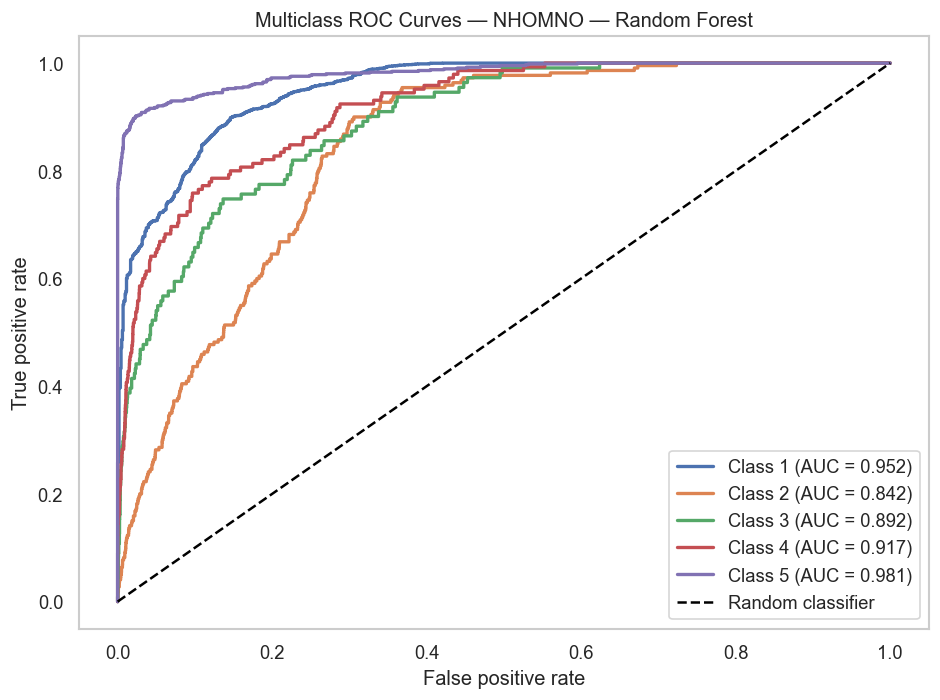

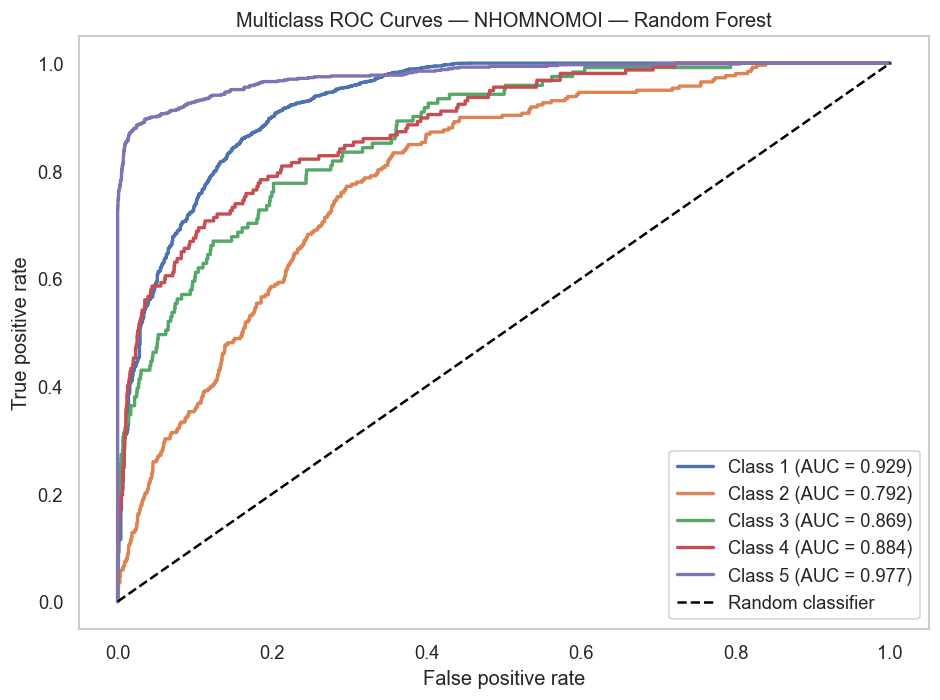

In [211]:
def plot_multiclass_roc(
    evaluation,
    y_true,
    title
):
    """
    Plot one-vs-rest ROC curves for each target class.
    """
    classes = evaluation["classes"]

    binary_target = label_binarize(
        y_true,
        classes=classes
    )

    probabilities = evaluation[
        "probabilities"
    ]

    plt.figure(figsize=(8, 6))

    for class_position, class_label in enumerate(
        classes
    ):
        false_positive_rate, true_positive_rate, _ = (
            roc_curve(
                binary_target[
                    :,
                    class_position
                ],
                probabilities[
                    :,
                    class_position
                ]
            )
        )

        class_auc = np.trapezoid(
            true_positive_rate,
            false_positive_rate
        )

        plt.plot(
            false_positive_rate,
            true_positive_rate,
            linewidth=2,
            label=(
                f"Class {class_label} "
                f"(AUC = {class_auc:.3f})"
            )
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="black",
        label="Random classifier"
    )

    plt.title(title)
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


for target_name in target_columns:
    random_forest_evaluation = (
        model_evaluations[
            (
                target_name,
                "Random Forest",
                "Baseline"
            )
        ]
    )

    plot_multiclass_roc(
        evaluation=random_forest_evaluation,
        y_true=model_splits[
            target_name
        ]["y_test"],
        title=(
            f"Multiclass ROC Curves — "
            f"{target_name} — Random Forest"
        )
    )

## 3.5. Hyperparameter Tuning

Hyperparameters are tuned using three deterministic group-aware folds constructed only from the development partition. Macro-F1 is the optimization criterion. The held-out test is not used by the search procedure or by final model selection.

In [212]:
# The deterministic CV row indices were created separately for each target in cell 3.2.
# They are passed directly to GridSearchCV, so fold membership is reproducible.
for target_name in target_columns:
    fold_sizes = [len(valid_rows) for _, valid_rows in model_splits[target_name]["cv_splits"]]
    print(f"{target_name} validation fold sizes: {fold_sizes}")

NHOMNO validation fold sizes: [7202, 7201, 7199]
NHOMNOMOI validation fold sizes: [7201, 7200, 7201]


### Logistic Regression Hyperparameters

The principal tuned parameter is `C`, the inverse of regularization strength:

- smaller `C`: stronger regularization;
- larger `C`: weaker regularization.

Other settings are held constant to ensure stable multinomial classification.

In [213]:
tuned_logistic_models = {}
logistic_best_parameters = {}
logistic_cv_summary = {}
logistic_cv_details = {}

logistic_c_values = [0.05, 0.20, 1.00]


def create_logistic_model(c_value):
    return Pipeline(steps=[
        ("preprocess", create_model_preprocessor(scale_numeric=True)),
        ("model", LogisticRegression(
            C=c_value,
            solver="lbfgs",
            class_weight="balanced",
            max_iter=1500,
            random_state=RANDOM_SEED,
        )),
    ])


for target_name in target_columns:
    split_data = model_splits[target_name]
    candidate_rows = []

    for c_value in logistic_c_values:
        fold_scores = []
        for fold_train, fold_valid in split_data["cv_splits"]:
            fold_model = create_logistic_model(c_value)
            fold_model.fit(
                split_data["X_train"].iloc[fold_train],
                split_data["y_train"].iloc[fold_train],
            )
            fold_prediction = fold_model.predict(
                split_data["X_train"].iloc[fold_valid]
            )
            fold_scores.append(f1_score(
                split_data["y_train"].iloc[fold_valid],
                fold_prediction,
                average="macro",
                zero_division=0,
            ))
            del fold_model, fold_prediction

        candidate_rows.append({
            "C": c_value,
            "Mean CV Macro F1": float(np.mean(fold_scores)),
            "Std CV Macro F1": float(np.std(fold_scores, ddof=1)),
            "Fold scores": fold_scores,
        })

    candidate_table = pd.DataFrame(candidate_rows).sort_values(
        "Mean CV Macro F1", ascending=False
    ).reset_index(drop=True)
    best_c = float(candidate_table.iloc[0]["C"])
    best_model = create_logistic_model(best_c)
    best_model.fit(split_data["X_train"], split_data["y_train"])

    tuned_logistic_models[target_name] = best_model
    logistic_best_parameters[target_name] = {"model__C": best_c}
    logistic_cv_details[target_name] = candidate_table

    baseline_score = float(
        candidate_table.loc[candidate_table["C"].eq(1.0), "Mean CV Macro F1"].iloc[0]
    )
    best_score = float(candidate_table.iloc[0]["Mean CV Macro F1"])
    logistic_cv_summary[target_name] = {
        "Baseline Logistic Regression": baseline_score,
        "Tuned Logistic Regression": best_score,
    }

    print(f"\nTarget: {target_name}")
    display(candidate_table.drop(columns=["Fold scores"]).style.format({
        "C": "{:.2f}", "Mean CV Macro F1": "{:.4f}", "Std CV Macro F1": "{:.4f}"
    }))
    print("Best parameters:", logistic_best_parameters[target_name])


Target: NHOMNO


,C,Mean CV Macro F1,Std CV Macro F1
0,0.20,0.4233,0.0042
1,1.00,0.4218,0.0054
2,0.05,0.4218,0.0026


Best parameters: {'model__C': 0.2}

Target: NHOMNOMOI


,C,Mean CV Macro F1,Std CV Macro F1
0,0.05,0.4200,0.0059
1,1.00,0.4166,0.0047
2,0.20,0.4162,0.0051


Best parameters: {'model__C': 0.05}


### Random Forest Hyperparameters

The Random Forest search compares a small, predeclared set of defensible configurations, including the baseline specification. This is more transparent and reproducible than drawing only a few random combinations from a much larger space.

In [214]:
tuned_random_forest_models = {}
random_forest_best_parameters = {}
random_forest_cv_summary = {}
random_forest_cv_details = {}

rf_candidate_configurations = [
    {
        "name": "Baseline Random Forest",
        "n_estimators": 60,
        "max_depth": 18,
        "min_samples_split": 2,
        "min_samples_leaf": 3,
        "max_features": "sqrt",
    },
    {
        "name": "Tuned Random Forest",
        "n_estimators": 100,
        "max_depth": 24,
        "min_samples_split": 4,
        "min_samples_leaf": 4,
        "max_features": 0.50,
    },
]


def create_random_forest_from_config(configuration):
    return Pipeline(steps=[
        ("preprocess", create_model_preprocessor(scale_numeric=False)),
        ("model", RandomForestClassifier(
            n_estimators=configuration["n_estimators"],
            max_depth=configuration["max_depth"],
            min_samples_split=configuration["min_samples_split"],
            min_samples_leaf=configuration["min_samples_leaf"],
            max_features=configuration["max_features"],
            class_weight="balanced_subsample",
            n_jobs=1,
            random_state=RANDOM_SEED,
        )),
    ])


for target_name in target_columns:
    split_data = model_splits[target_name]
    candidate_rows = []

    for configuration in rf_candidate_configurations:
        fold_scores = []
        for fold_number, (fold_train, fold_valid) in enumerate(
            split_data["cv_splits"], start=1
        ):
            fold_model = create_random_forest_from_config(configuration)
            fold_model.fit(
                split_data["X_train"].iloc[fold_train],
                split_data["y_train"].iloc[fold_train],
            )
            fold_prediction = fold_model.predict(
                split_data["X_train"].iloc[fold_valid]
            )
            fold_scores.append(f1_score(
                split_data["y_train"].iloc[fold_valid],
                fold_prediction,
                average="macro",
                zero_division=0,
            ))
            del fold_model, fold_prediction

        candidate_rows.append({
            **configuration,
            "Mean CV Macro F1": float(np.mean(fold_scores)),
            "Std CV Macro F1": float(np.std(fold_scores, ddof=1)),
            "Fold scores": fold_scores,
        })

    candidate_table = pd.DataFrame(candidate_rows).sort_values(
        "Mean CV Macro F1", ascending=False
    ).reset_index(drop=True)
    best_configuration = candidate_table.iloc[0].to_dict()

    best_model = create_random_forest_from_config(best_configuration)
    best_model.fit(split_data["X_train"], split_data["y_train"])

    tuned_random_forest_models[target_name] = best_model
    random_forest_best_parameters[target_name] = {
        key: best_configuration[key]
        for key in [
            "n_estimators", "max_depth", "min_samples_split",
            "min_samples_leaf", "max_features",
        ]
    }
    random_forest_cv_details[target_name] = candidate_table

    baseline_score = float(
        candidate_table.loc[
            candidate_table["name"].eq("Baseline Random Forest"),
            "Mean CV Macro F1",
        ].iloc[0]
    )
    best_score = float(best_configuration["Mean CV Macro F1"])
    random_forest_cv_summary[target_name] = {
        "Baseline Random Forest": baseline_score,
        "Tuned Random Forest": best_score,
    }

    print(f"\nTarget: {target_name}")
    display(candidate_table.drop(columns=["Fold scores"]).style.format({
        "Mean CV Macro F1": "{:.4f}", "Std CV Macro F1": "{:.4f}"
    }))
    print("Best configuration:", random_forest_best_parameters[target_name])


Target: NHOMNO


,name,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,Mean CV Macro F1,Std CV Macro F1
0,Tuned Random Forest,100,24,4,4,0.500000,0.5483,0.0108
1,Baseline Random Forest,60,18,2,3,sqrt,0.5171,0.0018


Best configuration: {'n_estimators': 100, 'max_depth': 24, 'min_samples_split': 4, 'min_samples_leaf': 4, 'max_features': 0.5}

Target: NHOMNOMOI


,name,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,Mean CV Macro F1,Std CV Macro F1
0,Tuned Random Forest,100,24,4,4,0.500000,0.5326,0.0014
1,Baseline Random Forest,60,18,2,3,sqrt,0.5124,0.0035


Best configuration: {'n_estimators': 100, 'max_depth': 24, 'min_samples_split': 4, 'min_samples_leaf': 4, 'max_features': 0.5}


In [215]:
for target_name in target_columns:
    split_data = model_splits[
        target_name
    ]

    tuned_model_pairs = {
        "Logistic Regression": (
            tuned_logistic_models[
                target_name
            ]
        ),
        "Random Forest": (
            tuned_random_forest_models[
                target_name
            ]
        )
    }

    for model_name, model in tuned_model_pairs.items():
        evaluation = evaluate_model(
            fitted_model=model,
            X_test=split_data["X_test"],
            y_test=split_data["y_test"],
            target_name=target_name,
            model_name=model_name,
            model_version="Tuned"
        )

        model_evaluations[
            (
                target_name,
                model_name,
                "Tuned"
            )
        ] = evaluation

        model_result_rows.append(
            evaluation["result"]
        )

all_model_results = pd.DataFrame(
    model_result_rows
)

metric_columns = [
    "Accuracy",
    "Balanced accuracy",
    "Macro precision",
    "Macro recall",
    "Macro F1",
    "Weighted F1",
    "AUC OvR macro",
    "Gini OvR macro",
    "Multiclass Brier",
    "Mean absolute class error",
    "Severe error rate"
]

display(
    all_model_results[
        [
            "Target",
            "Model",
            "Version",
            *metric_columns
        ]
    ].style.format({
        column: "{:.4f}"
        for column in metric_columns
    })
)

,Target,Model,Version,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,AUC OvR macro,Gini OvR macro,Multiclass Brier,Mean absolute class error,Severe error rate
0,NHOMNO,Logistic Regression,Baseline,0.6447,0.5185,0.4349,0.5185,0.4180,0.7332,0.8576,0.7153,0.4455,0.5803,0.1574
1,NHOMNO,Random Forest,Baseline,0.7120,0.6246,0.5328,0.6246,0.5219,0.7835,0.9170,0.8339,0.3353,0.3697,0.0495
2,NHOMNOMOI,Logistic Regression,Baseline,0.6205,0.5122,0.4347,0.5122,0.4140,0.7085,0.8385,0.6769,0.4837,0.6403,0.1791
3,NHOMNOMOI,Random Forest,Baseline,0.7244,0.5896,0.5189,0.5896,0.5144,0.7854,0.8900,0.7800,0.3851,0.3749,0.0611
4,NHOMNO,Logistic Regression,Tuned,0.6431,0.5146,0.4314,0.5146,0.4149,0.7307,0.8602,0.7203,0.4503,0.5827,0.1563
5,NHOMNO,Random Forest,Tuned,0.8303,0.5978,0.5365,0.5978,0.5494,0.8571,0.9205,0.8410,0.2382,0.2463,0.0472
6,NHOMNOMOI,Logistic Regression,Tuned,0.6323,0.5097,0.4284,0.5097,0.4155,0.7142,0.8436,0.6873,0.4996,0.6166,0.1637
7,NHOMNOMOI,Random Forest,Tuned,0.8263,0.5694,0.5324,0.5694,0.5413,0.8469,0.8939,0.7878,0.2654,0.2662,0.0552


In [216]:
baseline_comparison = (
    all_model_results[all_model_results["Version"] == "Baseline"]
    .set_index(["Target", "Model"])[metric_columns]
)
tuned_comparison = (
    all_model_results[all_model_results["Version"] == "Tuned"]
    .set_index(["Target", "Model"])[metric_columns]
)
tuning_change = (tuned_comparison - baseline_comparison).reset_index()

print("Held-out test change after tuning (Tuned minus Baseline):")
display(tuning_change.style.format({column: "{:+.4f}" for column in metric_columns}))

cv_selection_records = []
for target_name in target_columns:
    for candidate_name, score in {
        **logistic_cv_summary[target_name],
        **random_forest_cv_summary[target_name],
    }.items():
        cv_selection_records.append({
            "Target": target_name,
            "Candidate": candidate_name,
            "Development CV Macro F1": score,
        })

cv_selection_table = pd.DataFrame(cv_selection_records).sort_values(
    ["Target", "Development CV Macro F1"], ascending=[True, False]
).reset_index(drop=True)

print("Model-selection evidence (development CV only):")
display(cv_selection_table.style.format({"Development CV Macro F1": "{:.4f}"}))

Held-out test change after tuning (Tuned minus Baseline):


,Target,Model,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,AUC OvR macro,Gini OvR macro,Multiclass Brier,Mean absolute class error,Severe error rate
0,NHOMNO,Logistic Regression,-0.0017,-0.0039,-0.0035,-0.0039,-0.0031,-0.0025,+0.0025,+0.0050,+0.0048,+0.0024,-0.0011
1,NHOMNO,Random Forest,+0.1184,-0.0268,+0.0037,-0.0268,+0.0275,+0.0736,+0.0036,+0.0071,-0.0971,-0.1234,-0.0022
2,NHOMNOMOI,Logistic Regression,+0.0119,-0.0024,-0.0063,-0.0024,+0.0015,+0.0058,+0.0052,+0.0103,+0.0159,-0.0237,-0.0154
3,NHOMNOMOI,Random Forest,+0.1019,-0.0201,+0.0135,-0.0201,+0.0270,+0.0615,+0.0039,+0.0078,-0.1197,-0.1087,-0.0059


Model-selection evidence (development CV only):


,Target,Candidate,Development CV Macro F1
0,NHOMNO,Tuned Random Forest,0.5483
1,NHOMNO,Baseline Random Forest,0.5171
2,NHOMNO,Tuned Logistic Regression,0.4233
3,NHOMNO,Baseline Logistic Regression,0.4218
4,NHOMNOMOI,Tuned Random Forest,0.5326
5,NHOMNOMOI,Baseline Random Forest,0.5124
6,NHOMNOMOI,Tuned Logistic Regression,0.4200
7,NHOMNOMOI,Baseline Logistic Regression,0.4166


### Tuning Assessment

The table above separates two questions:

- **Development CV macro-F1** is used for model selection.
- **Held-out test metrics** are used only for final, unbiased performance reporting after the selection rule has been fixed.

A tuned model is retained only when its development cross-validation macro-F1 is better than the corresponding baseline configuration.

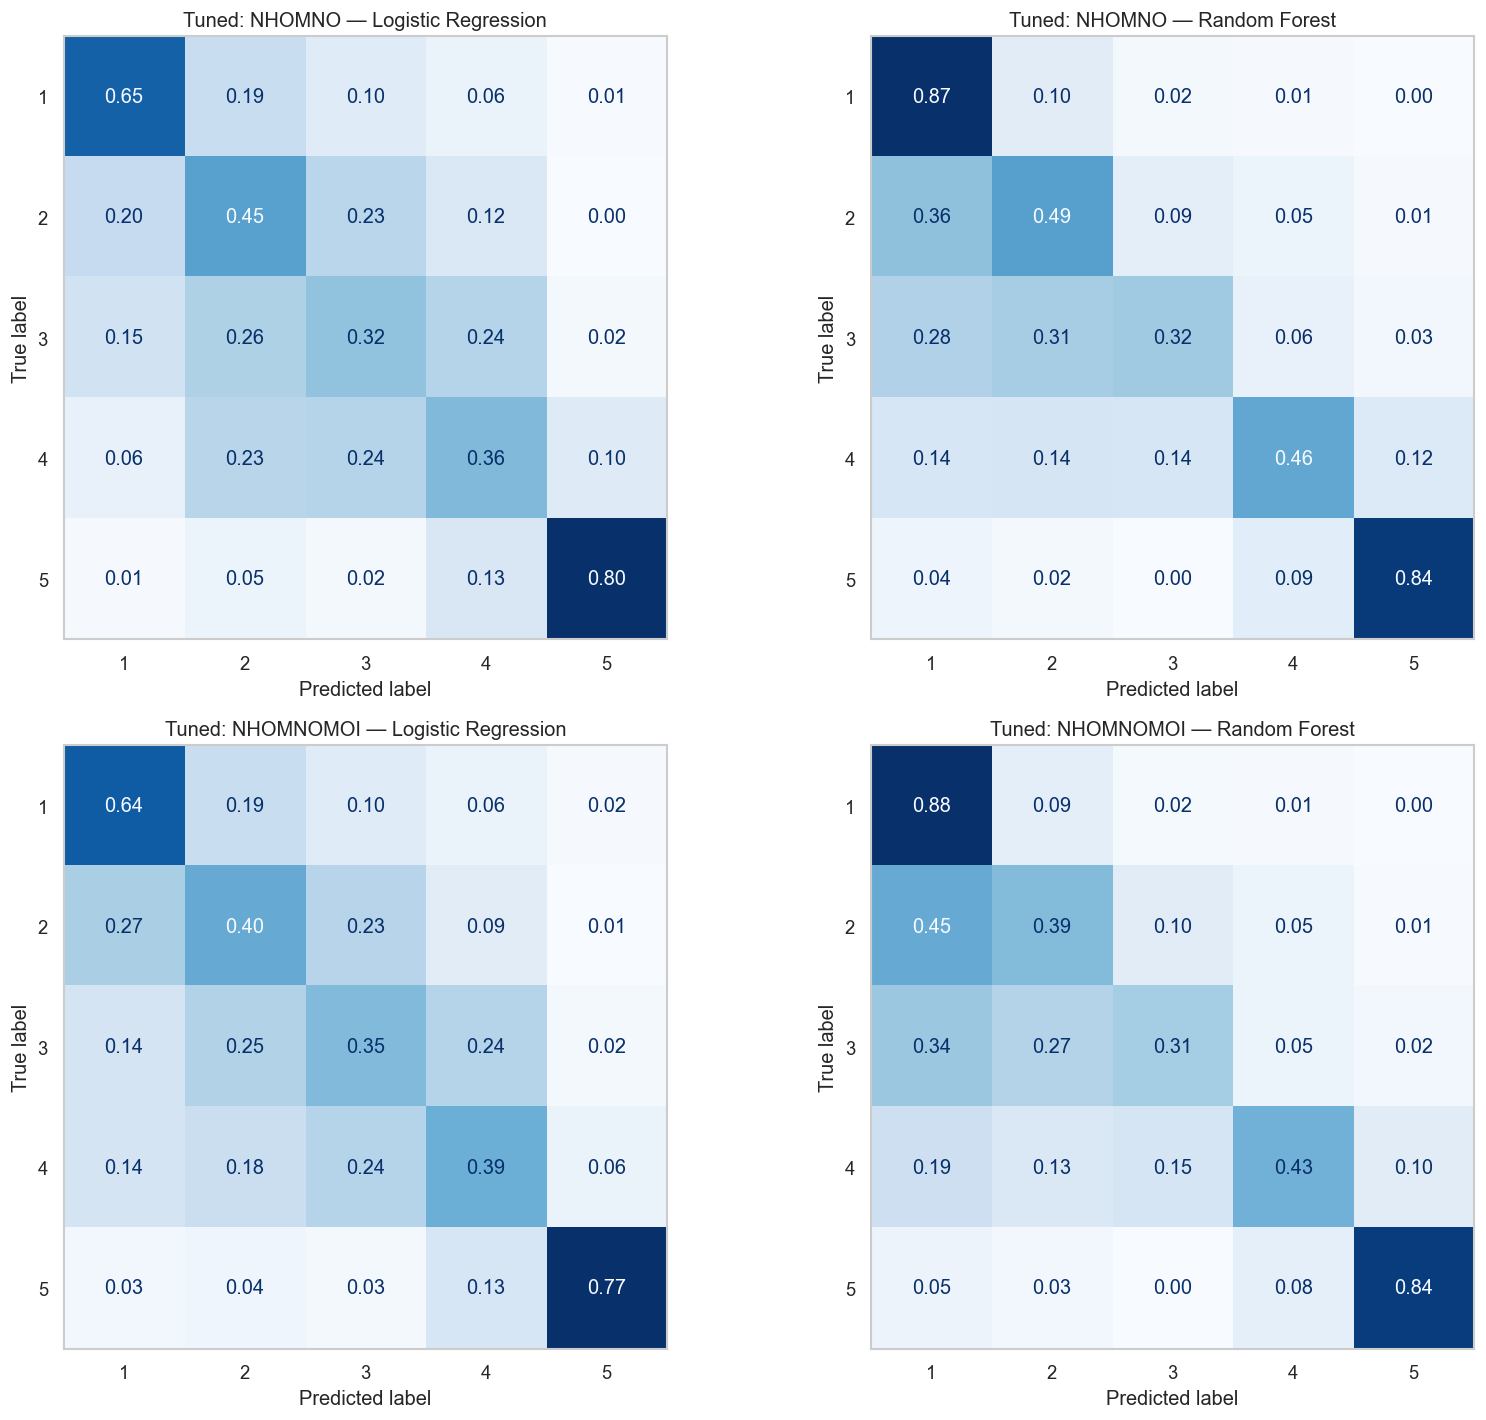

In [217]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 12)
)

for axis, (
    target_name,
    model_name
) in zip(
    axes.flatten(),
    plot_positions
):
    evaluation = model_evaluations[
        (
            target_name,
            model_name,
            "Tuned"
        )
    ]

    normalized_matrix = (
        evaluation["confusion_matrix"]
        / evaluation[
            "confusion_matrix"
        ].sum(
            axis=1,
            keepdims=True
        )
    )

    display_object = ConfusionMatrixDisplay(
        confusion_matrix=normalized_matrix,
        display_labels=(
            evaluation["classes"]
        )
    )

    display_object.plot(
        ax=axis,
        cmap="Blues",
        colorbar=False,
        values_format=".2f"
    )

    axis.set_title(
        f"Tuned: {target_name} — {model_name}"
    )

plt.tight_layout()
plt.show()

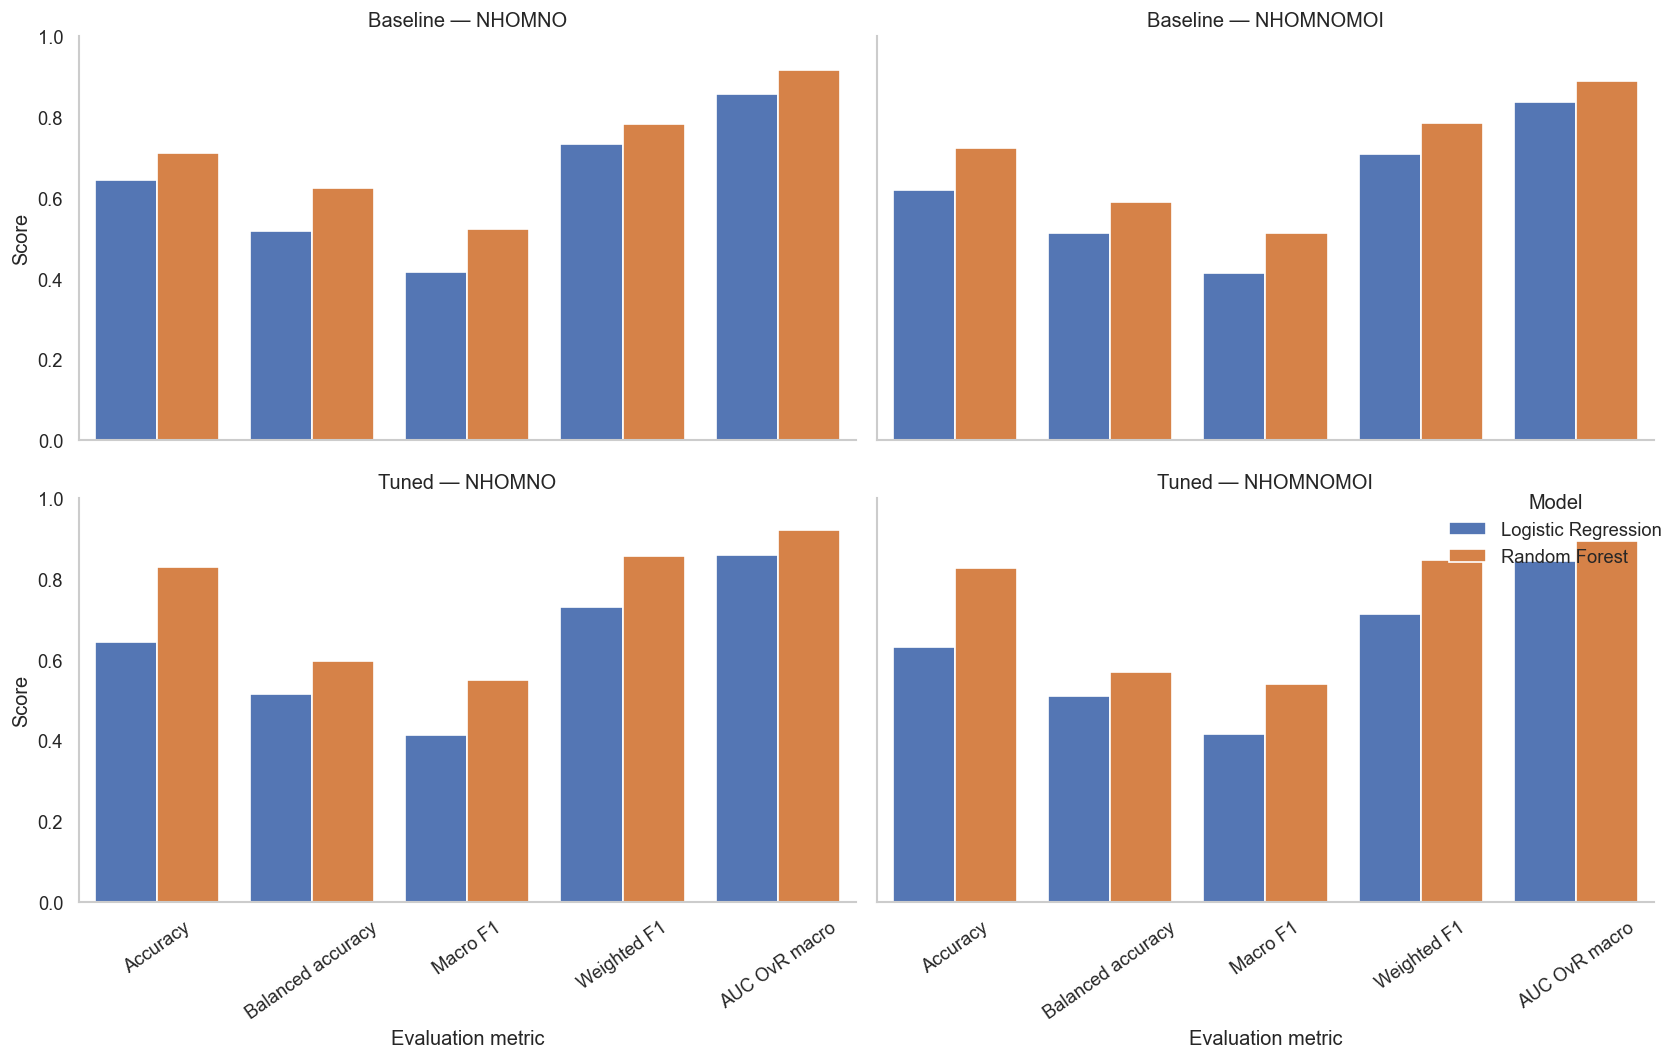

In [218]:
comparison_plot_data = (
    all_model_results.melt(
        id_vars=[
            "Target",
            "Model",
            "Version"
        ],
        value_vars=[
            "Accuracy",
            "Balanced accuracy",
            "Macro F1",
            "Weighted F1",
            "AUC OvR macro"
        ],
        var_name="Metric",
        value_name="Score"
    )
)

grid = sns.catplot(
    data=comparison_plot_data,
    x="Metric",
    y="Score",
    hue="Model",
    col="Target",
    row="Version",
    kind="bar",
    height=4.5,
    aspect=1.35,
    palette=[
        "#4472C4",
        "#ED7D31"
    ],
    sharey=True
)

grid.set_axis_labels(
    "Evaluation metric",
    "Score"
)

grid.set_titles(
    "{row_name} — {col_name}"
)

for axis in grid.axes.flatten():
    axis.tick_params(
        axis="x",
        rotation=35
    )
    axis.set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 3.6. Final Model Selection

The final model for each target is selected automatically using the highest **development cross-validation macro-F1**. Test accuracy, test macro-F1, test AUC, and the test confusion matrix are not used in this choice.

After selection, the chosen model is evaluated once on the common held-out test set. This prevents the earlier test-contamination problem caused by selecting baseline versus tuned models from test performance.

In [219]:
candidate_estimators = {}
for target_name in target_columns:
    candidate_estimators[target_name] = {
        "Baseline Logistic Regression": baseline_models[target_name]["Logistic Regression"],
        "Tuned Logistic Regression": tuned_logistic_models[target_name],
        "Baseline Random Forest": baseline_models[target_name]["Random Forest"],
        "Tuned Random Forest": tuned_random_forest_models[target_name],
    }

final_models = {}
final_model_versions = {}
final_model_rows = []

for target_name in target_columns:
    target_cv = cv_selection_table[cv_selection_table["Target"] == target_name]
    selected_candidate = target_cv.iloc[0]["Candidate"]
    selected_cv_score = float(target_cv.iloc[0]["Development CV Macro F1"])

    final_models[target_name] = candidate_estimators[target_name][selected_candidate]
    final_model_versions[target_name] = selected_candidate

    if "Logistic Regression" in selected_candidate:
        model_name = "Logistic Regression"
    else:
        model_name = "Random Forest"
    version = "Tuned" if selected_candidate.startswith("Tuned") else "Baseline"

    selected_result = model_evaluations[(target_name, model_name, version)]["result"].copy()
    selected_result["Development CV Macro F1"] = selected_cv_score
    final_model_rows.append(selected_result)

final_model_results = pd.DataFrame(final_model_rows)

display(final_model_results[[
    "Target", "Model", "Version", "Development CV Macro F1", *metric_columns
]].style.format({
    "Development CV Macro F1": "{:.4f}",
    **{column: "{:.4f}" for column in metric_columns},
}))

print("Final models selected without using the held-out test:")
for target_name, version in final_model_versions.items():
    print(f"- {target_name}: {version}")

,Target,Model,Version,Development CV Macro F1,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,AUC OvR macro,Gini OvR macro,Multiclass Brier,Mean absolute class error,Severe error rate
0,NHOMNO,Random Forest,Tuned,0.5483,0.8303,0.5978,0.5365,0.5978,0.5494,0.8571,0.9205,0.8410,0.2382,0.2463,0.0472
1,NHOMNOMOI,Random Forest,Tuned,0.5326,0.8263,0.5694,0.5324,0.5694,0.5413,0.8469,0.8939,0.7878,0.2654,0.2662,0.0552


Final models selected without using the held-out test:
- NHOMNO: Tuned Random Forest
- NHOMNOMOI: Tuned Random Forest


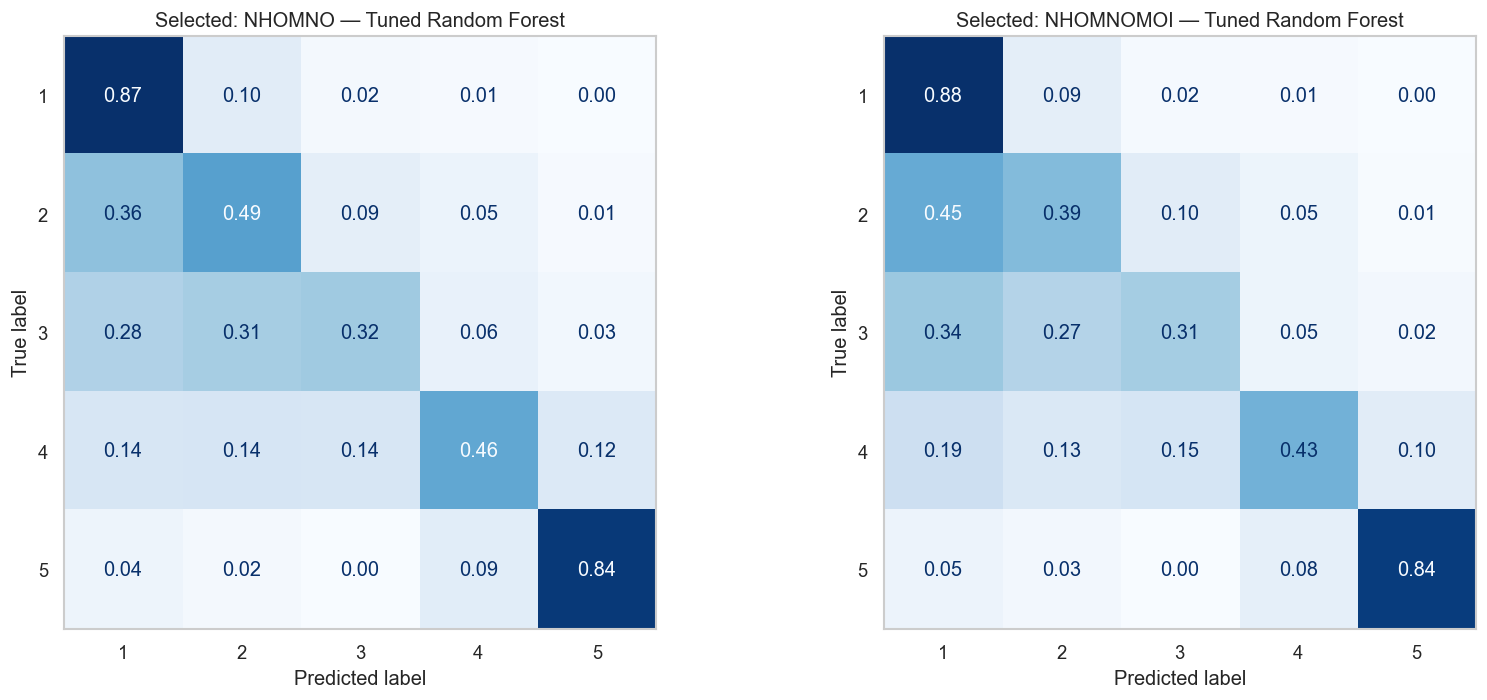


Selected model class report — NHOMNO — Tuned Random Forest


,precision,recall,f1-score,support
1,0.9590,0.8721,0.9135,4268.0000
2,0.1803,0.4909,0.2637,220.0000
3,0.2466,0.3243,0.2802,111.0000
4,0.3564,0.4621,0.4024,145.0000
5,0.9402,0.8397,0.8871,655.0000
accuracy,0.8303,0.8303,0.8303,0.8303
macro avg,0.5365,0.5978,0.5494,5399.0000
weighted avg,0.8942,0.8303,0.8571,5399.0000



Selected model class report — NHOMNOMOI — Tuned Random Forest


,precision,recall,f1-score,support
1,0.9428,0.8812,0.9110,4192.0000
2,0.1869,0.3876,0.2522,258.0000
3,0.2420,0.3140,0.2734,121.0000
4,0.3472,0.4268,0.3829,157.0000
5,0.9430,0.8376,0.8871,671.0000
accuracy,0.8263,0.8263,0.8263,0.8263
macro avg,0.5324,0.5694,0.5413,5399.0000
weighted avg,0.8737,0.8263,0.8469,5399.0000


In [220]:
plt.rcParams["axes.grid"] = False

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)

for axis, target_name in zip(
    axes,
    target_columns
):
    selected_candidate = final_model_versions[
        target_name
    ]

    model_name = (
        "Logistic Regression"
        if "Logistic Regression" in selected_candidate
        else "Random Forest"
    )

    version = (
        "Tuned"
        if selected_candidate.startswith("Tuned")
        else "Baseline"
    )

    evaluation = model_evaluations[
        (
            target_name,
            model_name,
            version
        )
    ]

    matrix = evaluation[
        "confusion_matrix"
    ].astype(float)

    row_totals = matrix.sum(
        axis=1,
        keepdims=True
    )

    normalized_matrix = np.divide(
        matrix,
        row_totals,
        out=np.zeros_like(matrix),
        where=row_totals != 0
    )

    display_object = ConfusionMatrixDisplay(
        confusion_matrix=normalized_matrix,
        display_labels=evaluation["classes"]
    )

    display_object.plot(
        ax=axis,
        cmap="Blues",
        colorbar=False,
        values_format=".2f"
    )

    axis.grid(False)
    axis.xaxis.grid(
        False,
        which="both"
    )
    axis.yaxis.grid(
        False,
        which="both"
    )
    axis.minorticks_off()

    axis.set_title(
        f"Selected: {target_name} — "
        f"{selected_candidate}"
    )

plt.tight_layout()
plt.show()


for target_name in target_columns:
    selected_candidate = final_model_versions[
        target_name
    ]

    model_name = (
        "Logistic Regression"
        if "Logistic Regression" in selected_candidate
        else "Random Forest"
    )

    version = (
        "Tuned"
        if selected_candidate.startswith("Tuned")
        else "Baseline"
    )

    report_table = pd.DataFrame(
        model_evaluations[
            (
                target_name,
                model_name,
                version
            )
        ]["classification_report"]
    ).T

    print(
        f"\nSelected model class report — "
        f"{target_name} — {selected_candidate}"
    )

    display(
        report_table.style.format(
            "{:.4f}"
        )
    )

### Logistic Regression Coefficient Check

The traditional model is retained as an interpretable benchmark. The table below reports the largest absolute standardized log-odds coefficients for each debt group. Coefficient signs indicate model association conditional on the other encoded predictors; they do not establish causality.

In [221]:
for target_name in target_columns:
    fitted_lr = tuned_logistic_models[target_name]
    preprocessor = fitted_lr.named_steps["preprocess"]
    classifier = fitted_lr.named_steps["model"]
    transformed_names = preprocessor.get_feature_names_out()

    coefficient_rows = []
    for class_position, class_label in enumerate(classifier.classes_):
        class_coefficients = pd.Series(
            classifier.coef_[class_position], index=transformed_names
        )
        top_indices = class_coefficients.abs().nlargest(5).index
        for feature_name in top_indices:
            coefficient_rows.append({
                "Target": target_name,
                "Class": class_label,
                "Encoded feature": feature_name,
                "Coefficient": class_coefficients.loc[feature_name],
                "Absolute coefficient": abs(class_coefficients.loc[feature_name]),
            })

    coefficient_table = pd.DataFrame(coefficient_rows).sort_values(
        ["Class", "Absolute coefficient"], ascending=[True, False]
    )
    print(f"\nLargest Logistic Regression coefficients — {target_name}")
    display(coefficient_table.style.format({
        "Coefficient": "{:+.4f}", "Absolute coefficient": "{:.4f}"
    }))


Largest Logistic Regression coefficients — NHOMNO


,Target,Class,Encoded feature,Coefficient,Absolute coefficient
0,NHOMNO,1,categorical__CURRMIACCTTYPCD_GC01,+4.7649,4.7649
1,NHOMNO,1,categorical__CURRMIACCTTYPCD_NH02,-2.6392,2.6392
2,NHOMNO,1,categorical__CURRMIACCTTYPCD_XQ11,-1.8959,1.8959
3,NHOMNO,1,categorical__CURRMIACCTTYPCD_VS02,+1.5336,1.5336
4,NHOMNO,1,categorical__ORGNBR_119,-1.5128,1.5128
5,NHOMNO,2,categorical__ORGNBR_101,+1.3615,1.3615
6,NHOMNO,2,categorical__ORGNBR_66,+1.1540,1.1540
7,NHOMNO,2,categorical__CURRMIACCTTYPCD_VS01,+1.1271,1.1271
8,NHOMNO,2,categorical__ORGNBR_96,-1.0999,1.0999
9,NHOMNO,2,categorical__ORGNBR_128,+1.0646,1.0646



Largest Logistic Regression coefficients — NHOMNOMOI


,Target,Class,Encoded feature,Coefficient,Absolute coefficient
0,NHOMNOMOI,1,categorical__CURRMIACCTTYPCD_GC01,+1.9369,1.9369
1,NHOMNOMOI,1,categorical__CURRMIACCTTYPCD_NH02,-1.5241,1.5241
2,NHOMNOMOI,1,categorical__ORGNBR_119,-1.0151,1.0151
3,NHOMNOMOI,1,numerical__DUE_YEAR,+0.8286,0.8286
4,NHOMNOMOI,1,categorical__CURRMIACCTTYPCD_XQ11,-0.8252,0.8252
5,NHOMNOMOI,2,categorical__CURRMIACCTTYPCD_VS01,+0.7229,0.7229
6,NHOMNOMOI,2,categorical__ORGNBR_101,+0.6334,0.6334
7,NHOMNOMOI,2,categorical__CURRMIACCTTYPCD_TH01,+0.6333,0.6333
8,NHOMNOMOI,2,categorical__ORGNBR_66,+0.6260,0.6260
9,NHOMNOMOI,2,categorical__ORGNBR_55,-0.5204,0.5204


## 3.7. Temporal Sensitivity Analysis

The main rubric evaluation uses the common group-aware holdout. Because the OOS data are concentrated in later origination years and year variables are important predictors, an additional out-of-time stress test is reported.

Models are trained on observations opened no later than 2017 and evaluated on 2018–2019 observations. This is a sensitivity check rather than a replacement for a formally defined performance window. Records from 2020 are excluded from this check because the labeled data contain too few such observations.

In [222]:
temporal_results = []
open_year_series = prepared_training_data["OPEN_YEAR"]
temporal_train_mask = open_year_series.le(2017)
temporal_test_mask = open_year_series.between(2018, 2019, inclusive="both")

print("Temporal training observations (<=2017):", int(temporal_train_mask.sum()))
print("Temporal test observations (2018-2019):", int(temporal_test_mask.sum()))

for target_name in target_columns:
    temporal_model = clone(final_models[target_name])
    temporal_model.fit(X_model.loc[temporal_train_mask], training_data.loc[temporal_train_mask, target_name])
    temporal_evaluation = evaluate_model(
        fitted_model=temporal_model,
        X_test=X_model.loc[temporal_test_mask],
        y_test=training_data.loc[temporal_test_mask, target_name],
        target_name=target_name,
        model_name=final_model_versions[target_name],
        model_version="Out-of-time sensitivity",
    )
    temporal_results.append(temporal_evaluation["result"])

temporal_results_df = pd.DataFrame(temporal_results)
display(temporal_results_df[["Target", *metric_columns]].style.format({
    column: "{:.4f}" for column in metric_columns
}))

print(
    "Interpretation: materially weaker temporal results would indicate that the random "
    "holdout is optimistic for later loan vintages and that OOS predictions require caution."
)

Temporal training observations (<=2017): 11766
Temporal test observations (2018-2019): 15230


,Target,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,AUC OvR macro,Gini OvR macro,Multiclass Brier,Mean absolute class error,Severe error rate
0,NHOMNO,0.8166,0.3670,0.2798,0.3670,0.3015,0.8366,0.6731,0.3463,0.4554,0.3560,0.0941
1,NHOMNOMOI,0.6932,0.3355,0.2680,0.3355,0.2775,0.7488,0.6323,0.2646,0.5150,0.5221,0.1293


Interpretation: materially weaker temporal results would indicate that the random holdout is optimistic for later loan vintages and that OOS predictions require caution.


## 3.8. Conclusion

Random Forest and Multinomial Logistic Regression are compared under the same leakage-safe holdout and deterministic group-aware cross-validation. Final model selection uses development CV macro-F1 only, while the test set is reserved for final reporting.

Macro-F1, balanced accuracy, class-level recall, calibration, and severity-aware errors should be considered together. High overall accuracy alone is not sufficient because debt group 1 dominates the sample. The temporal sensitivity test is especially important because the OOS population is concentrated in later origination years.

All model results describe predictive association within the supplied data. They do not establish causal effects or justify automated credit approval without business validation, governance, and an official target-performance definition.

# Question 4 — Model Deployment and Out-of-Sample Prediction

In [223]:
from sklearn.inspection import permutation_importance

# Reuse the portable paths, preprocessing helpers, selected models and fixed test split
# created in Questions 2 and 3. Do not redefine them with machine-specific paths.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Question 4 environment ready.")
print("Prediction file:", PREDICTION_FILE.resolve())

## 4.1. Read the Training and Out-of-Sample Data

The labeled dataset is read from the `saoke_td_ct` worksheet. The out-of-sample dataset is stored separately because its original observations and order must be preserved in the final prediction file.

In [224]:
if not TRAIN_FILE.is_file():
    raise FileNotFoundError(f"Training file not found: {TRAIN_FILE}")
if not OOS_FILE.is_file():
    raise FileNotFoundError(f"Out-of-sample file not found: {OOS_FILE}")

training_raw = pd.read_excel(TRAIN_FILE, sheet_name="saoke_td_ct")
oos_raw = pd.read_csv(OOS_FILE, encoding="utf-8-sig", dtype=str)

original_oos_columns = oos_raw.columns.tolist()
oos_original_order = oos_raw.copy(deep=True)

print("Training data shape:", training_raw.shape)
print("Out-of-sample data shape:", oos_raw.shape)
print("Number of original OOS columns:", len(original_oos_columns))
display(training_raw.head())
display(oos_raw.head())

Training data shape: (27001, 21)
Out-of-sample data shape: (25000, 18)
Number of original OOS columns: 18


In [225]:
TARGET_COLUMNS = ["NHOMNO", "NHOMNOMOI"]

MODEL_FEATURES = [
    "DUE_YEAR",
    "CURRMIACCTTYPCD",
    "LAISUAT",
    "LOAN_TERM_DAYS",
    "MUCDICHVAY",
    "OPEN_YEAR",
    "ORGNBR",
    "MJACCTTYPCD",
    "LOG_CURR_BAL",
    "LOG_BASE_BAL",
    "PARENTORGNBR",
]

RAW_REQUIRED_COLUMNS = [
    "OPEN_DATE",
    "NGAYDENHAN",
    "LAISUAT",
    "CURR_BAL",
    "BASE_BAL",
    "CURRMIACCTTYPCD",
    "MUCDICHVAY",
    "ORGNBR",
    "MJACCTTYPCD",
    "PARENTORGNBR",
]

missing_training_columns = sorted(
    set(RAW_REQUIRED_COLUMNS + TARGET_COLUMNS) - set(training_raw.columns)
)

missing_oos_columns = sorted(
    set(RAW_REQUIRED_COLUMNS) - set(oos_raw.columns)
)

if missing_training_columns:
    raise ValueError(
        f"Missing columns in the training data: {missing_training_columns}"
    )

if missing_oos_columns:
    raise ValueError(
        f"Missing columns in the out-of-sample data: {missing_oos_columns}"
    )

unexpected_oos_targets = [
    column for column in TARGET_COLUMNS if column in oos_raw.columns
]

if unexpected_oos_targets:
    raise ValueError(
        "The OOS data already contain target columns: "
        f"{unexpected_oos_targets}"
    )

print("All required columns are available.")

All required columns are available.


## 4.2. Reproduce the Feature Engineering Process

The same `prepare_credit_features` function used during development is reused directly. This prevents the development and deployment code paths from silently diverging.

In [226]:
required_helpers = [
    parse_mixed_excel_date,
    convert_decimal_numeric,
    normalize_integer_code,
    normalize_text_category,
    prepare_credit_features,
]
if not all(callable(helper) for helper in required_helpers):
    raise RuntimeError("One or more feature-engineering helpers are unavailable.")
print("Reusing the validated feature-engineering functions from Question 2.")

Reusing the validated feature-engineering functions from Question 2.


In [227]:
# Restrict training inputs to columns also available in the OOS data
training_input_raw = training_raw[
    original_oos_columns
].copy()

# Apply the corrected feature-engineering function
training_prepared = prepare_credit_features(
    training_input_raw
)

oos_prepared = prepare_credit_features(
    oos_raw
)

# Check whether all model features were successfully created
missing_engineered_training = sorted(
    set(MODEL_FEATURES) - set(training_prepared.columns)
)

missing_engineered_oos = sorted(
    set(MODEL_FEATURES) - set(oos_prepared.columns)
)

if missing_engineered_training:
    raise ValueError(
        "Missing engineered training features: "
        f"{missing_engineered_training}"
    )

if missing_engineered_oos:
    raise ValueError(
        "Missing engineered OOS features: "
        f"{missing_engineered_oos}"
    )

# Verify that feature engineering did not change the row counts
if len(training_prepared) != len(training_raw):
    raise ValueError(
        "Training row count changed during feature engineering."
    )

if len(oos_prepared) != len(oos_raw):
    raise ValueError(
        "OOS row count changed during feature engineering."
    )

# Summarize missing values after feature engineering
feature_quality = pd.DataFrame(
    {
        "Training missing": (
            training_prepared[MODEL_FEATURES]
            .isna()
            .sum()
        ),
        "Training missing (%)": (
            training_prepared[MODEL_FEATURES]
            .isna()
            .mean()
            .mul(100)
        ),
        "OOS missing": (
            oos_prepared[MODEL_FEATURES]
            .isna()
            .sum()
        ),
        "OOS missing (%)": (
            oos_prepared[MODEL_FEATURES]
            .isna()
            .mean()
            .mul(100)
        ),
    }
)

print("Feature engineering completed successfully.")
print("Training data shape:", training_prepared.shape)
print("OOS data shape:", oos_prepared.shape)

display(feature_quality)

Feature engineering completed successfully.
Training data shape: (27001, 27)
OOS data shape: (25000, 27)


,Training missing,Training missing (%),OOS missing,OOS missing (%)
DUE_YEAR,0,0.0000,0,0.0000
CURRMIACCTTYPCD,0,0.0000,0,0.0000
LAISUAT,0,0.0000,0,0.0000
LOAN_TERM_DAYS,7,0.0259,101,0.4040
MUCDICHVAY,0,0.0000,0,0.0000
OPEN_YEAR,0,0.0000,0,0.0000
ORGNBR,0,0.0000,0,0.0000
MJACCTTYPCD,0,0.0000,0,0.0000
LOG_CURR_BAL,0,0.0000,0,0.0000
LOG_BASE_BAL,0,0.0000,0,0.0000


## 4.3. Define the Selected Model Pipelines

Categorical variables are imputed and one-hot encoded. Unknown categories in the out-of-sample dataset are ignored safely. Numeric missing values are replaced by the median estimated from the training data.

All preprocessing operations are contained in the pipeline to prevent data leakage.

In [228]:
CATEGORICAL_FEATURES = model_categorical_features.copy()
NUMERIC_FEATURES = model_numeric_features.copy()
MODEL_FEATURES = model_features.copy()


def create_selected_model(target):
    """Return an unfitted clone of the model selected by development CV in Question 3."""
    if target not in final_models:
        raise ValueError(f"Unsupported target variable: {target}")
    return clone(final_models[target])


selected_model_summary = final_model_results[[
    "Target", "Model", "Version", "Development CV Macro F1", "Macro F1",
    "Balanced accuracy", "AUC OvR macro", "Multiclass Brier",
]].copy()
selected_model_summary["Selected specification"] = selected_model_summary.apply(
    lambda row: final_model_versions[row["Target"]], axis=1
)
display(selected_model_summary.style.format({
    "Development CV Macro F1": "{:.4f}", "Macro F1": "{:.4f}",
    "Balanced accuracy": "{:.4f}", "AUC OvR macro": "{:.4f}",
    "Multiclass Brier": "{:.4f}",
}))

,Target,Model,Version,Development CV Macro F1,Macro F1,Balanced accuracy,AUC OvR macro,Multiclass Brier,Selected specification
0,NHOMNO,Random Forest,Tuned,0.5483,0.5494,0.5978,0.9205,0.2382,Tuned Random Forest
1,NHOMNOMOI,Random Forest,Tuned,0.5326,0.5413,0.5694,0.8939,0.2654,Tuned Random Forest


## 4.4. Estimate Permutation Importance on Held-Out Data

Permutation importance is calculated from each selected model fitted only on the development partition and evaluated on the common held-out test. A balanced test subsample is used only to keep computation manageable and to prevent group 1 from dominating the interpretation score. Importance indicates predictive contribution, not causality.

In [229]:
X_full = training_prepared[MODEL_FEATURES].copy()
importance_tables = {}
interpretation_models = {}

for target in TARGET_COLUMNS:
    interpretation_model = final_models[target]
    interpretation_models[target] = interpretation_model

    X_interpret_test = model_splits[target]["X_test"].copy()
    y_interpret_test = model_splits[target]["y_test"].copy()

    interpretation_sample = pd.concat(
        [X_interpret_test, y_interpret_test.rename("__target__")], axis=1
    )
    minimum_class_size = int(interpretation_sample["__target__"].value_counts().min())
    sample_size_per_class = min(500, minimum_class_size)
    interpretation_sample = (
        interpretation_sample.groupby("__target__", group_keys=False)
        .sample(n=sample_size_per_class, random_state=RANDOM_SEED)
    )

    permutation_result = permutation_importance(
        estimator=interpretation_model,
        X=interpretation_sample[MODEL_FEATURES],
        y=interpretation_sample["__target__"],
        scoring="f1_macro",
        n_repeats=5,
        random_state=RANDOM_SEED,
        n_jobs=1,
    )

    importance_table = pd.DataFrame({
        "Feature": MODEL_FEATURES,
        "Importance_mean": permutation_result.importances_mean,
        "Importance_std": permutation_result.importances_std,
    }).sort_values("Importance_mean", ascending=False).reset_index(drop=True)
    importance_table["Rank"] = np.arange(1, len(importance_table) + 1)
    importance_tables[target] = importance_table

    print(f"\nTop 10 features for {target} (balanced sample: {len(interpretation_sample)} rows)")
    display(importance_table.head(10))


Top 10 features for NHOMNO (balanced sample: 555 rows)


,Feature,Importance_mean,Importance_std,Rank
0,DUE_YEAR,0.2585,0.0155,1
1,LOAN_TERM_DAYS,0.0982,0.0122,2
2,LOG_CURR_BAL,0.0654,0.0089,3
3,LOG_BASE_BAL,0.0496,0.0073,4
4,LAISUAT,0.0347,0.0092,5
5,CURRMIACCTTYPCD,0.0301,0.0065,6
6,PARENTORGNBR,0.0189,0.0049,7
7,MUCDICHVAY,0.0175,0.0038,8
8,OPEN_YEAR,0.0115,0.0046,9
9,ORGNBR,0.0095,0.0045,10



Top 10 features for NHOMNOMOI (balanced sample: 605 rows)


,Feature,Importance_mean,Importance_std,Rank
0,DUE_YEAR,0.2333,0.0160,1
1,LOAN_TERM_DAYS,0.1166,0.0151,2
2,LOG_CURR_BAL,0.0619,0.0117,3
3,LOG_BASE_BAL,0.0502,0.0070,4
4,CURRMIACCTTYPCD,0.0371,0.0079,5
5,LAISUAT,0.0235,0.0111,6
6,PARENTORGNBR,0.0232,0.0049,7
7,ORGNBR,0.0154,0.0048,8
8,OPEN_YEAR,0.0146,0.0061,9
9,MUCDICHVAY,0.0008,0.0033,10


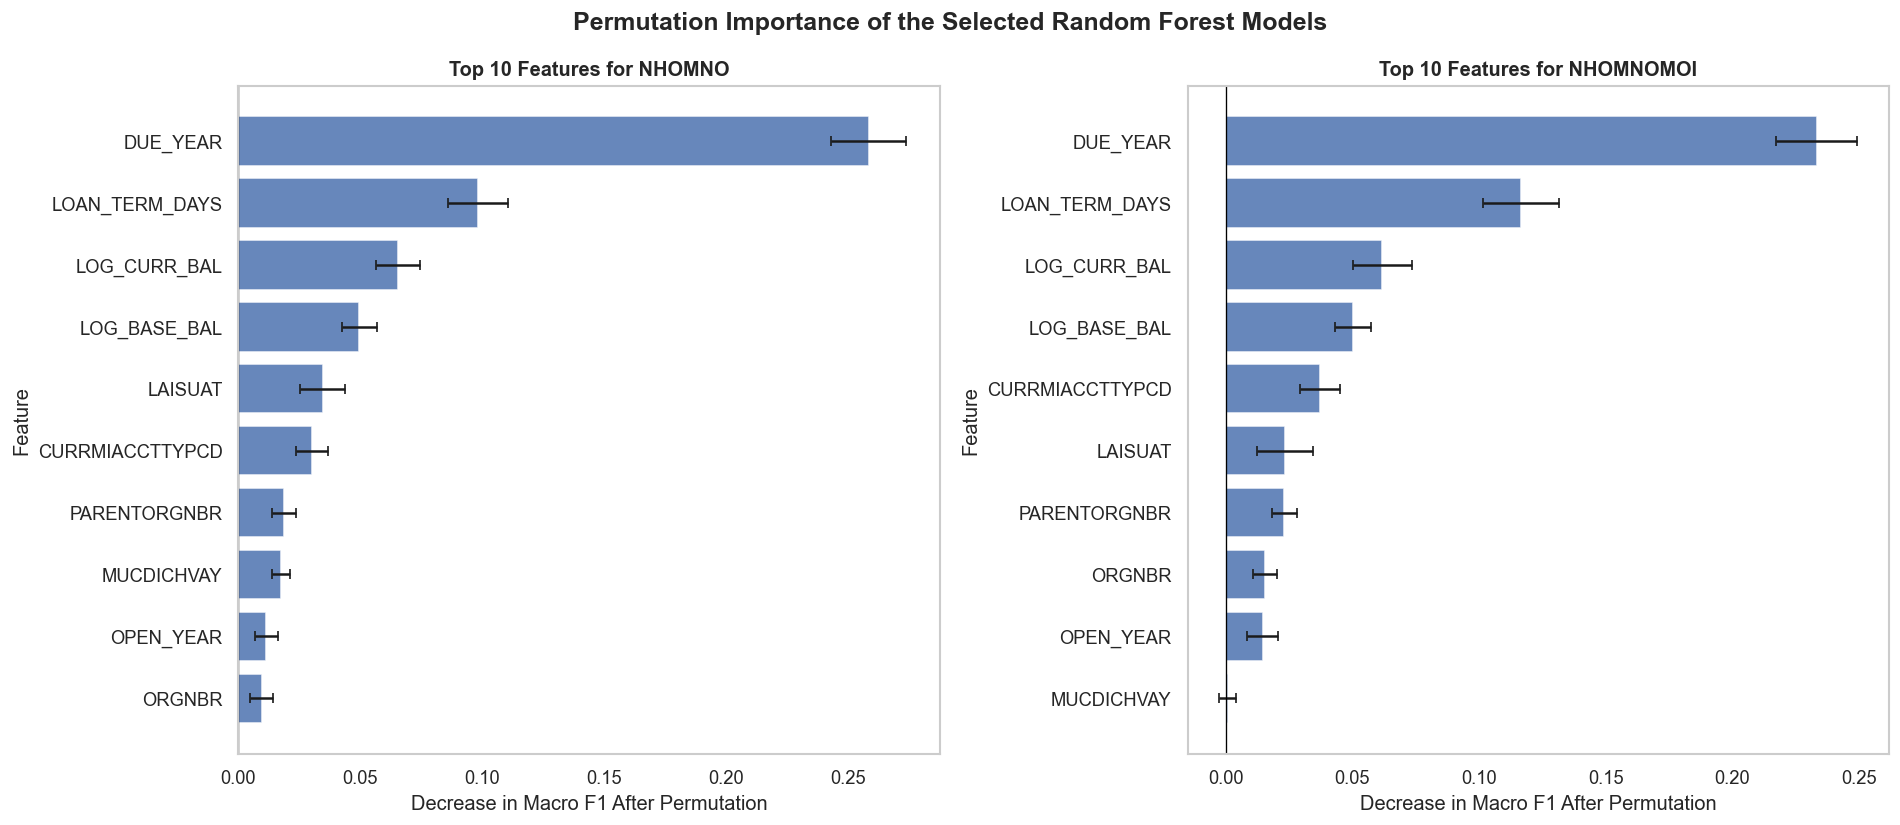

In [230]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 7),
)

for axis, target in zip(axes, TARGET_COLUMNS):
    top_features = (
        importance_tables[target]
        .head(10)
        .sort_values("Importance_mean", ascending=True)
    )

    axis.barh(
        top_features["Feature"],
        top_features["Importance_mean"],
        xerr=top_features["Importance_std"],
        alpha=0.85,
        capsize=3,
    )

    axis.axvline(
        x=0,
        color="black",
        linewidth=0.8,
    )

    axis.set_title(
        f"Top 10 Features for {target}",
        fontweight="bold",
    )
    axis.set_xlabel("Decrease in Macro F1 After Permutation")
    axis.set_ylabel("Feature")

plt.suptitle(
    "Permutation Importance of the Selected Random Forest Models",
    fontsize=15,
    fontweight="bold",
)

plt.tight_layout()
plt.show()

In [231]:
importance_comparison = (
    importance_tables["NHOMNO"][
        ["Feature", "Importance_mean"]
    ]
    .rename(
        columns={
            "Importance_mean": "NHOMNO_importance"
        }
    )
    .merge(
        importance_tables["NHOMNOMOI"][
            ["Feature", "Importance_mean"]
        ].rename(
            columns={
                "Importance_mean": "NHOMNOMOI_importance"
            }
        ),
        on="Feature",
        how="outer",
    )
    .fillna(0)
)

importance_comparison["Average_importance"] = (
    importance_comparison[
        ["NHOMNO_importance", "NHOMNOMOI_importance"]
    ].mean(axis=1)
)

overall_top_10 = (
    importance_comparison
    .sort_values(
        "Average_importance",
        ascending=False,
    )
    .head(10)
    .reset_index(drop=True)
)

overall_top_10.insert(
    0,
    "Overall_rank",
    np.arange(1, len(overall_top_10) + 1),
)

display(
    overall_top_10.style.format(
        {
            "NHOMNO_importance": "{:.4f}",
            "NHOMNOMOI_importance": "{:.4f}",
            "Average_importance": "{:.4f}",
        }
    )
)

,Overall_rank,Feature,NHOMNO_importance,NHOMNOMOI_importance,Average_importance
0,1,DUE_YEAR,0.2585,0.2333,0.2459
1,2,LOAN_TERM_DAYS,0.0982,0.1166,0.1074
2,3,LOG_CURR_BAL,0.0654,0.0619,0.0636
3,4,LOG_BASE_BAL,0.0496,0.0502,0.0499
4,5,CURRMIACCTTYPCD,0.0301,0.0371,0.0336
5,6,LAISUAT,0.0347,0.0235,0.0291
6,7,PARENTORGNBR,0.0189,0.0232,0.0210
7,8,OPEN_YEAR,0.0115,0.0146,0.0130
8,9,ORGNBR,0.0095,0.0154,0.0124
9,10,MUCDICHVAY,0.0175,0.0008,0.0092


### Interpretation

The permutation-importance results identify the variables that contribute most strongly to the classification of the two debt-group targets. A higher value means that disturbing the information contained in that variable produces a larger decline in macro F1-score.

Feature importance reflects predictive contribution rather than a causal relationship. Therefore, the results should be interpreted as evidence that the variables help distinguish credit-risk groups, not as proof that they cause deterioration in credit quality.

In [232]:
feature_implications = {
    "DUE_YEAR": (
        "Represents the scheduled maturity period and may capture "
        "differences in remaining repayment horizons."
    ),
    "OPEN_YEAR": (
        "Reflects loan origination timing and may distinguish loan "
        "vintages exposed to different economic conditions."
    ),
    "LOAN_TERM_DAYS": (
        "Measures contractual maturity and may reflect differences "
        "in repayment burden and credit exposure duration."
    ),
    "LAISUAT": (
        "Represents the interest rate and therefore affects the "
        "borrower's financing cost and repayment burden."
    ),
    "LOG_CURR_BAL": (
        "Represents the current outstanding exposure after reducing "
        "balance skewness through a logarithmic transformation."
    ),
    "LOG_BASE_BAL": (
        "Represents the original or reference credit exposure and "
        "provides information about loan size."
    ),
    "CURRMIACCTTYPCD": (
        "Identifies the current detailed account type and may capture "
        "product-specific credit-risk characteristics."
    ),
    "MJACCTTYPCD": (
        "Identifies the main credit-account category and may distinguish "
        "risk patterns across lending products."
    ),
    "MUCDICHVAY": (
        "Represents loan purpose, which may be associated with different "
        "cash-flow sources and repayment risks."
    ),
    "ORGNBR": (
        "Represents the originating unit and may capture differences in "
        "customer composition, underwriting, or local risk conditions."
    ),
    "PARENTORGNBR": (
        "Represents the parent organizational unit and may capture "
        "broader portfolio or regional risk differences."
    ),
}

top_10_with_implications = overall_top_10.copy()

top_10_with_implications["Practical_implication"] = (
    top_10_with_implications["Feature"]
    .map(feature_implications)
)

display(
    top_10_with_implications[
        [
            "Overall_rank",
            "Feature",
            "Average_importance",
            "Practical_implication",
        ]
    ].style.format(
        {
            "Average_importance": "{:.4f}"
        }
    )
)

,Overall_rank,Feature,Average_importance,Practical_implication
0,1,DUE_YEAR,0.2459,Represents the scheduled maturity period and may capture differences in remaining repayment horizons.
1,2,LOAN_TERM_DAYS,0.1074,Measures contractual maturity and may reflect differences in repayment burden and credit exposure duration.
2,3,LOG_CURR_BAL,0.0636,Represents the current outstanding exposure after reducing balance skewness through a logarithmic transformation.
3,4,LOG_BASE_BAL,0.0499,Represents the original or reference credit exposure and provides information about loan size.
4,5,CURRMIACCTTYPCD,0.0336,Identifies the current detailed account type and may capture product-specific credit-risk characteristics.
5,6,LAISUAT,0.0291,Represents the interest rate and therefore affects the borrower's financing cost and repayment burden.
6,7,PARENTORGNBR,0.0210,Represents the parent organizational unit and may capture broader portfolio or regional risk differences.
7,8,OPEN_YEAR,0.0130,Reflects loan origination timing and may distinguish loan vintages exposed to different economic conditions.
8,9,ORGNBR,0.0124,"Represents the originating unit and may capture differences in customer composition, underwriting, or local risk conditions."
9,10,MUCDICHVAY,0.0092,"Represents loan purpose, which may be associated with different cash-flow sources and repayment risks."


## 4.5. Re-estimate the Selected Models Using All Labeled Observations

After the model specifications are selected and their held-out performance is reported, unfitted clones are trained on all labeled observations for deployment to OOS. The OOS data are never used to fit preprocessing or model parameters.

In [233]:
deployment_models = {}
oos_predictions = {}

for target in TARGET_COLUMNS:
    deployment_model = create_selected_model(target)
    deployment_model.fit(X_full, training_raw[target])
    target_prediction = deployment_model.predict(oos_prepared[MODEL_FEATURES])

    numeric_prediction = pd.to_numeric(pd.Series(target_prediction), errors="coerce")
    if numeric_prediction.notna().all() and np.allclose(numeric_prediction, np.round(numeric_prediction)):
        target_prediction = np.round(numeric_prediction).astype("int64").to_numpy()

    deployment_models[target] = deployment_model
    oos_predictions[target] = target_prediction

    print(f"\nPrediction distribution for {target}:")
    prediction_distribution = (
        pd.Series(target_prediction, name=target)
        .value_counts(dropna=False).sort_index().rename("Count").to_frame()
    )
    prediction_distribution["Percentage"] = (
        prediction_distribution["Count"] / len(target_prediction) * 100
    )
    display(prediction_distribution)


Prediction distribution for NHOMNO:


,Count,Percentage
NHOMNO,,
1,7242,28.9680
2,501,2.0040
3,5096,20.3840
4,11992,47.9680
5,169,0.6760



Prediction distribution for NHOMNOMOI:


,Count,Percentage
NHOMNOMOI,,
1,7369,29.4760
2,464,1.8560
3,5259,21.0360
4,11756,47.0240
5,152,0.6080


In [234]:
prediction_validation = []

for target in TARGET_COLUMNS:
    training_classes = set(
        pd.Series(training_raw[target])
        .dropna()
        .astype(str)
    )

    predicted_classes = set(
        pd.Series(oos_predictions[target])
        .dropna()
        .astype(str)
    )

    unexpected_classes = sorted(
        predicted_classes - training_classes
    )

    prediction_validation.append(
        {
            "Target": target,
            "Number_of_predictions": len(
                oos_predictions[target]
            ),
            "Missing_predictions": int(
                pd.Series(
                    oos_predictions[target]
                ).isna().sum()
            ),
            "Training_classes": sorted(training_classes),
            "Predicted_classes": sorted(predicted_classes),
            "Unexpected_classes": unexpected_classes,
        }
    )

prediction_validation_df = pd.DataFrame(
    prediction_validation
)

display(prediction_validation_df)

if prediction_validation_df["Missing_predictions"].sum() > 0:
    raise ValueError("Missing OOS predictions were detected.")

if prediction_validation_df["Unexpected_classes"].apply(bool).any():
    raise ValueError("Unexpected predicted classes were detected.")

print("Prediction validation completed successfully.")

,Target,Number_of_predictions,Missing_predictions,Training_classes,Predicted_classes,Unexpected_classes
0,NHOMNO,25000,0,"[1, 2, 3, 4, 5]","[1, 2, 3, 4, 5]",[]
1,NHOMNOMOI,25000,0,"[1, 2, 3, 4, 5]","[1, 2, 3, 4, 5]",[]


Prediction validation completed successfully.


## 4.6. Export the Out-of-Sample Forecast File

The final file retains all original out-of-sample observations in their original order. The two forecast columns are appended at the end of the dataset.

In [235]:
forecast_output = oos_original_order.copy(deep=True)

forecast_output["NHOMNO"] = oos_predictions["NHOMNO"]
forecast_output["NHOMNOMOI"] = oos_predictions["NHOMNOMOI"]

expected_output_columns = (
    original_oos_columns
    + ["NHOMNO", "NHOMNOMOI"]
)

if forecast_output.columns.tolist() != expected_output_columns:
    raise ValueError(
        "The output column order does not match the required structure."
    )

if len(forecast_output) != len(oos_original_order):
    raise ValueError(
        "The output row count differs from the original OOS data."
    )

# Verify that every original value remains unchanged and in the same order
pd.testing.assert_frame_equal(
    forecast_output[original_oos_columns].reset_index(drop=True),
    oos_original_order[original_oos_columns].reset_index(drop=True),
    check_dtype=True,
    check_names=True,
)

if forecast_output[TARGET_COLUMNS].isna().any().any():
    raise ValueError("The forecast file contains missing predictions.")

forecast_output.to_csv(
    PREDICTION_FILE,
    index=False,
    encoding="utf-8-sig",
)

print("Prediction file exported successfully.")
print("File location:", PREDICTION_FILE.resolve())
print("Output shape:", forecast_output.shape)
print("Original row order preserved: Yes")
print("Missing predictions:", forecast_output[TARGET_COLUMNS].isna().sum().sum())

display(forecast_output.head())

In [236]:
exported_predictions = pd.read_csv(
    PREDICTION_FILE,
    encoding="utf-8-sig",
)

final_export_check = pd.DataFrame(
    {
        "Check": [
            "CSV file exists",
            "Correct number of rows",
            "Correct number of columns",
            "NHOMNO is present",
            "NHOMNOMOI is present",
            "No missing NHOMNO predictions",
            "No missing NHOMNOMOI predictions",
        ],
        "Result": [
            PREDICTION_FILE.is_file(),
            len(exported_predictions) == len(oos_original_order),
            len(exported_predictions.columns)
            == len(original_oos_columns) + 2,
            "NHOMNO" in exported_predictions.columns,
            "NHOMNOMOI" in exported_predictions.columns,
            exported_predictions["NHOMNO"].isna().sum() == 0,
            exported_predictions["NHOMNOMOI"].isna().sum() == 0,
        ],
    }
)

display(final_export_check)

if not final_export_check["Result"].all():
    raise ValueError(
        "At least one final export validation check failed."
    )

print("All final export checks passed.")

,Check,Result
0,CSV file exists,True
1,Correct number of rows,True
2,Correct number of columns,True
3,NHOMNO is present,True
4,NHOMNOMOI is present,True
5,No missing NHOMNO predictions,True
6,No missing NHOMNOMOI predictions,True


All final export checks passed.


## Conclusion for Question 4

The final OOS file preserves every original input column and row in its original order, then appends `NHOMNO` and `NHOMNOMOI`. All preprocessing is fitted on labeled data only, and the deployed estimator is an unfitted clone of the specification selected by development CV.

The predictions must be interpreted cautiously because the OOS origination-year distribution differs substantially from the labeled sample. They are model forecasts, not evidence of causal risk drivers or a substitute for an official credit decision policy.